In [1]:
import pandas as pd
import numpy as np
import pickle
import SimpleITK as sitk
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
import seaborn as sns
import os
from iblatlas.regions import BrainRegions
import torch
import torch.nn as nn
import torch.optim as optim
import random
from tqdm import tqdm
import torch.nn.functional as F
from torch.optim import lr_scheduler
import time

In [2]:
df_layers = pd.read_excel('SEU_net_wo_corticalLayers.xlsx', header=1, index_col=1)
df_layers = df_layers.iloc[:, 1:]
df_layers

,FRP,MOp,MOs,SSp-n,SSp-bfd,SSp-ll,SSp-m,SSp-ul,SSp-tr,SSp-un,...,MD,SMT,PVT,RE,CM,RT,PSV,PB,TRN,PRNr
FRP,0.000000,0.000000,2.028292,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0,0,0,0.000000
MOp,0.625221,1.992551,1.765525,0.930700,0.678581,1.968629,1.024268,0.953173,1.600363,0.961477,...,0.000000,0.000000,0.0,0.000000,0.0,0.861023,0,0,0,0.875238
MOs,1.417198,1.381516,1.645074,0.670320,2.725806,0.853611,1.209884,1.446972,0.000000,0.000000,...,0.000000,1.621683,0.0,0.000000,0.0,0.768877,0,0,0,0.000000
SSp-n,0.000000,0.789537,1.283165,1.795210,1.301726,0.000000,1.947067,2.399795,0.000000,1.158404,...,0.000000,0.000000,0.0,0.000000,0.0,0.810396,0,0,0,0.000000
SSp-bfd,0.000000,1.159698,0.766737,1.669994,1.934520,0.447926,1.166723,0.869816,3.467967,1.047941,...,0.000000,0.000000,0.0,0.000000,0.0,0.191446,0,0,0,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
RT,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,1.514522,2.131420,0.0,4.582369,0.0,0.762490,0,0,0,0.000000
PSV,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0,0,0,0.720976
PB,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0,0,0,1.214098
TRN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0,0,0,0.000000


## 1. Stage1

In [3]:
with open('brain_region_wo_layer_stage1.pkl', 'rb') as f:
    C_traces = pickle.load(f)
C_traces

{'MG': {'spike_times': array([0.        , 0.        , 0.        , ..., 0.99999854, 0.99999971,
         1.        ]),
  'spike_voltages': array([0.00026798, 0.00013078, 0.0001027 , ..., 0.00013102, 0.00018679,
         0.00014846])},
 'LGd': {'spike_times': array([0., 0., 0., ..., 1., 1., 1.]),
  'spike_voltages': array([0.0001613 , 0.0001284 , 0.00018691, ..., 0.00011591, 0.00022138,
         0.00010917])},
 'CEA': {'spike_times': array([0.00000000e+00, 1.35276967e-06, 1.55804080e-06, ...,
         9.99996026e-01, 9.99997624e-01, 1.00000000e+00]),
  'spike_voltages': array([3.35663608e-05, 6.50536604e-05, 1.05790488e-04, ...,
         6.90313609e-05, 6.91710375e-05, 5.53253303e-05])},
 'VPM': {'spike_times': array([0., 0., 0., ..., 1., 1., 1.]),
  'spike_voltages': array([7.28509549e-05, 1.54141395e-04, 1.58252820e-04, ...,
         2.98089057e-04, 3.47912486e-04, 2.16961940e-04])},
 'CA3': {'spike_times': array([0.        , 0.        , 0.        , ..., 0.99999981, 1.        ,
       

In [4]:
len(C_traces)

89

In [5]:
keys = list(C_traces.keys())

df_filtered = df_layers.loc[df_layers.index.intersection(keys), df_layers.columns.intersection(keys)]
scaler = MinMaxScaler()
df_scaled = pd.DataFrame(
    scaler.fit_transform(df_filtered),
    index=df_filtered.index,
    columns=df_filtered.columns
)
df_scaled

,FRP,MOp,MOs,SSp-n,SSp-bfd,SSp-ll,SSp-m,SSp-ul,SSp-tr,SSp-un,...,LD,MD,SMT,PVT,CM,RT,PSV,PB,TRN,PRNr
FRP,0.000000,0.000000,0.614604,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000
MOp,0.441167,0.378662,0.534982,0.281224,0.237631,0.211517,0.242158,0.083040,0.402819,0.297850,...,0.096450,0.000000,0.000000,0.0,0.0,0.372428,0.0,0.0,0.0,0.720896
MOs,1.000000,0.262542,0.498483,0.202547,0.954544,0.091715,0.286042,0.126060,0.000000,0.000000,...,0.000000,0.000000,0.208482,0.0,0.0,0.332571,0.0,0.0,0.0,0.000000
SSp-n,0.000000,0.150043,0.388819,0.542448,0.455849,0.000000,0.460327,0.209069,0.000000,0.358855,...,0.040574,0.000000,0.000000,0.0,0.0,0.350530,0.0,0.0,0.0,0.000000
SSp-bfd,0.000000,0.220388,0.232333,0.504613,0.677445,0.048127,0.275838,0.075778,0.872903,0.324635,...,0.597337,0.000000,0.000000,0.0,0.0,0.082808,0.0,0.0,0.0,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
RT,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,1.000000,0.477782,0.274014,0.0,0.0,0.329808,0.0,0.0,0.0,0.000000
PSV,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0,0.593837
PB,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0,1.000000
TRN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000


In [6]:
df_scaled.to_csv("./result/wo_layer/stage1/df_scaled.csv", index=True)

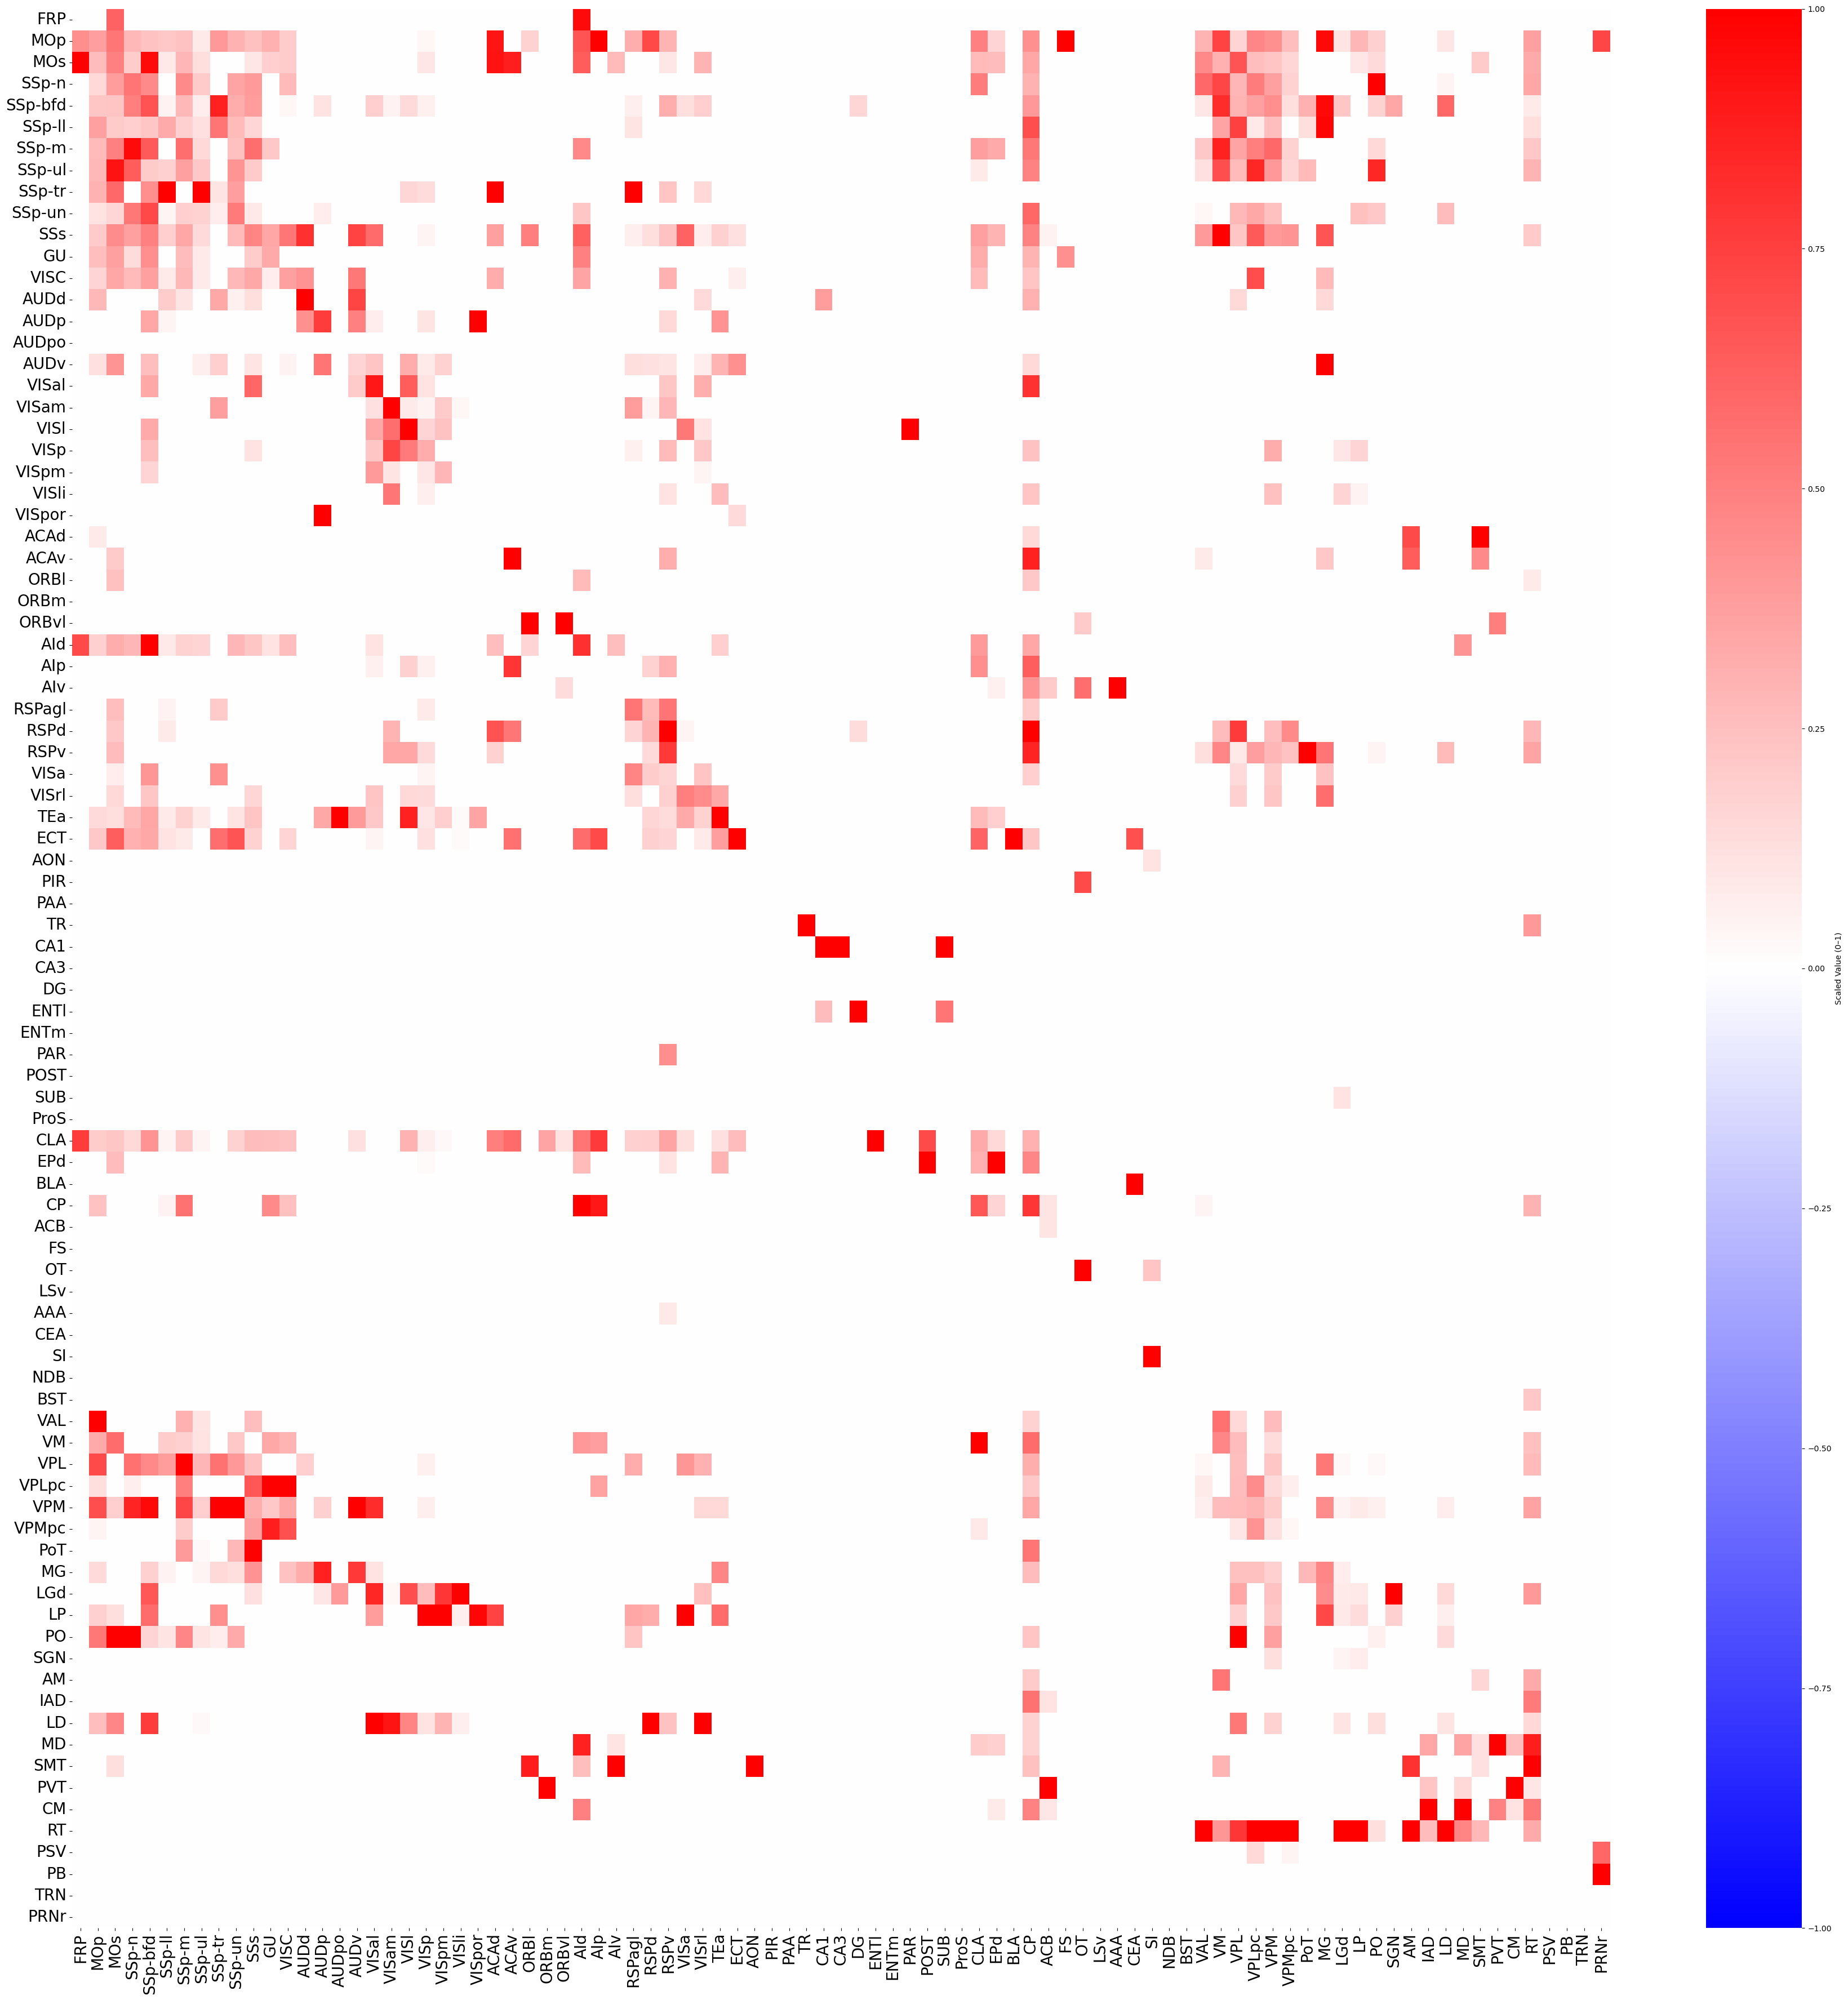

In [5]:
plt.figure(figsize=(max(10, len(df_scaled.columns) * 0.4),
                    max(8, len(df_scaled.index) * 0.4)))

ax = sns.heatmap(df_scaled, cmap='bwr', cbar_kws={'label': 'Scaled Value (0–1)'}, 
                 xticklabels=True, yticklabels=True,vmin=-1,vmax=1)

ax.set_xticks([x + 0.5 for x in range(len(df_scaled.columns))])
ax.set_xticklabels(df_scaled.columns, rotation=90, fontsize=20)

ax.set_yticks([y + 0.5 for y in range(len(df_scaled.index))])
ax.set_yticklabels(df_scaled.index, rotation=0, fontsize=20)

plt.title("", fontsize=14)
plt.tight_layout()
plt.show()

In [6]:
def build_region_binned_traces_nan(aligned_region_data,
                                   dt=0.01,
                                   duration_mode='percentile',
                                   duration_percentile=100):

    end_times = []
    for rid, d in aligned_region_data.items():
        t = d.get('spike_times', None)
        if t is None or len(t) == 0:
            end_times.append(0.0)
        else:
            end_times.append(float(np.max(t)))
    end_times = np.array(end_times)

    if duration_mode == 'min':
        used_duration = float(np.min(end_times))
    elif duration_mode == 'median':
        used_duration = float(np.median(end_times))
    elif duration_mode == 'percentile':
        used_duration = float(np.percentile(end_times, duration_percentile))
    elif duration_mode == 'max':
        used_duration = float(np.max(end_times))
    else:
        raise ValueError("duration_mode must be 'min'|'median'|'percentile'|'max'")

    if used_duration <= 0:
        raise ValueError("used_duration <= 0, check your data")

    edges = np.arange(0.0, used_duration + dt, dt)
    centers = edges[:-1] + dt / 2.0
    n_bins = len(centers)

    binned = {}
    for rid, d in aligned_region_data.items():
        times = np.asarray(d.get('spike_times', []))
        volts = d.get('spike_voltages', None)

        region_bin = np.full(n_bins, np.nan, dtype=float)

        if times.size == 0:
            binned[rid] = region_bin
            continue

        mask = (times >= 0) & (times < used_duration)
        times_cut = times[mask]
        if volts is not None:
            volts_cut = np.asarray(volts)[mask]
        else:
            volts_cut = None

        bin_indices = np.digitize(times_cut, edges) - 1
        valid = (bin_indices >= 0) & (bin_indices < n_bins)
        bin_indices = bin_indices[valid]
        if volts_cut is not None:
            volts_cut = volts_cut[valid]
            sums = np.zeros(n_bins)
            counts = np.zeros(n_bins)
            np.add.at(sums, bin_indices, volts_cut)
            np.add.at(counts, bin_indices, 1)
            avg = np.divide(sums, counts, out=np.full_like(sums, np.nan), where=counts > 0)
            region_bin = avg
        else:
            counts = np.zeros(n_bins)
            np.add.at(counts, bin_indices, 1)
            region_bin[counts > 0] = counts[counts > 0]  

        binned[rid] = region_bin

    return centers, binned, used_duration


#################################################
C_traces_sorted = {k: C_traces[k] for k in df_scaled.index if k in C_traces}
time_axis, binned_traces, duration = build_region_binned_traces_nan(C_traces_sorted, dt=0.001)

Automatically set line spacing: 2.20


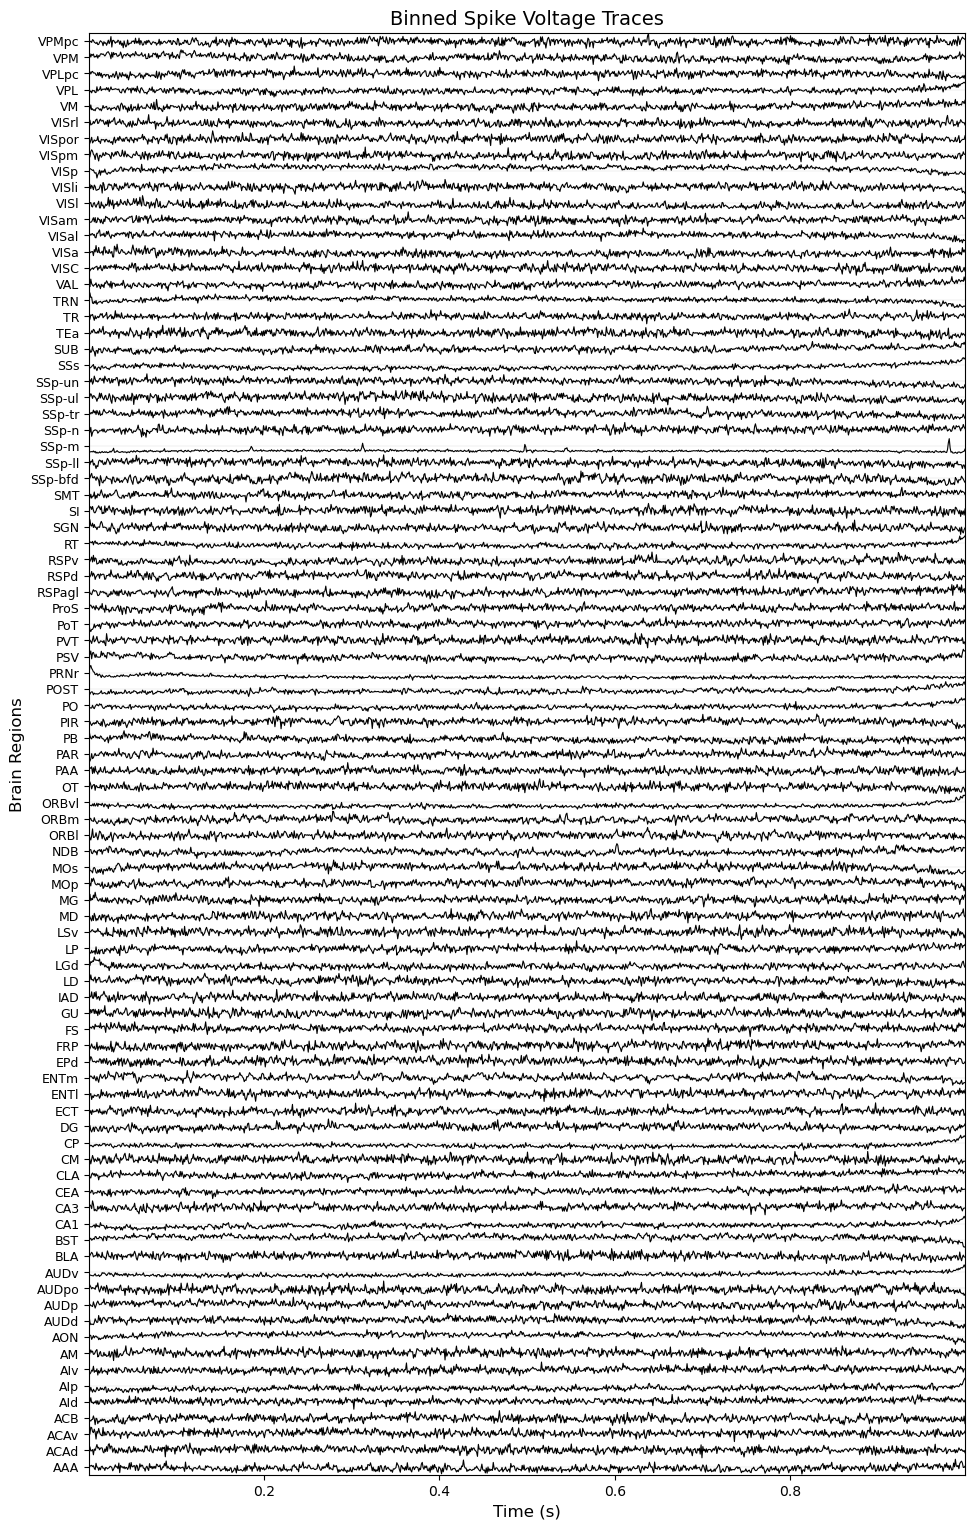

In [7]:
def plot_brain_region_traces(binned_traces, time_axis, output_dir="result/wo_layer/stage1",
                             auto_spacing=True, compact=True, dpi=600):

    region_names = sorted(list(binned_traces.keys()))
    region_ids = region_names  

    scaled_traces = []
    max_amplitudes = []

    for name in region_names:
        trace = np.nan_to_num(binned_traces[name])
        if np.max(trace) - np.min(trace) > 0:
            trace_scaled = (trace - np.min(trace)) / (np.max(trace) - np.min(trace)) * 2 - 1
        else:
            trace_scaled = trace
        scaled_traces.append(trace_scaled)
        max_amplitudes.append(np.max(np.abs(trace_scaled)))

    if auto_spacing:
        mean_amp = np.median(max_amplitudes)
        offset_step = 2.2 * mean_amp  
    else:
        offset_step = 2.0
    print(f"Automatically set line spacing: {offset_step:.2f}")

    fig_height = max(3, len(region_names) * 0.18)
    fig, ax = plt.subplots(figsize=(12, fig_height))

    for i, trace_scaled in enumerate(scaled_traces):
        base = i * offset_step
        ax.axhline(base, color='gray', lw=0.3, alpha=0.3)
        ax.plot(time_axis, trace_scaled + base, lw=0.8, color="black")

    ytick_positions = np.arange(0, len(region_names) * offset_step, offset_step)
    ax.set_yticks(ytick_positions)
    ax.set_yticklabels(region_names, fontsize=9)

    ax.set_xlabel("Time (s)", fontsize=12)
    ax.set_ylabel("Brain Regions", fontsize=12)
    ax.set_title("Binned Spike Voltage Traces", fontsize=14)

    if compact:
        ax.set_ylim(-offset_step * 0.5, len(region_names) * offset_step - offset_step * 0.5)
        plt.margins(x=0, y=0.01)
        plt.subplots_adjust(left=0.25, right=0.98, top=0.95, bottom=0.05)
    else:
        plt.tight_layout(pad=0.3)

    os.makedirs(output_dir, exist_ok=True)
    output_path = os.path.join(output_dir, "all_trace_stage_1.png")
    plt.savefig(output_path, dpi=dpi, bbox_inches="tight")
    plt.show()
############################################################################################
plot_brain_region_traces(binned_traces, time_axis, output_dir="result/wo_layer/stage1")

In [8]:
# ----------------- Seed -----------------
def set_seed(seed=42):
    import random, os
    import numpy as np
    import torch

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.benchmark = True
    torch.backends.cudnn.deterministic = False

# ----------------- Graph-leaning -----------------
class SimpleGraphLearn(nn.Module):
    def __init__(self, node_dim, nodes, dropout=0.5, struct_connectome=None):
        super(SimpleGraphLearn, self).__init__()
        self.nodes = nodes
        self.dropout = dropout
        
        self.gate_net = nn.Sequential(
            nn.Linear(node_dim * 2, node_dim),
            nn.Sigmoid()
        )
        
        self.attention = nn.Linear(node_dim, 1, bias=False)
        self.norm = nn.LayerNorm(nodes)
        
        self.w = nn.Parameter(torch.zeros(size=(nodes, node_dim)))
        nn.init.xavier_uniform_(self.w.data, gain=1.414)
        
        if struct_connectome is not None:
            self.struct_connectome = nn.Parameter(
                torch.FloatTensor(struct_connectome), 
                requires_grad=False
            )
        else:
            self.struct_connectome = None
            
        self.graph_weight = nn.Parameter(torch.ones(1))
        self.struct_weight = nn.Parameter(torch.ones(1))
        
    def forward(self, node_features, temporal_features=None, batch_size=1):
        batch_size, nodes, node_dim = node_features.shape
        
        if temporal_features is not None:
            concat_features = torch.cat([node_features, temporal_features], dim=-1)  # (B, N, 2*D)
            gate = self.gate_net(concat_features)  # (B, N, D)
            node_features = gate * node_features + (1 - gate) * temporal_features
        
        node_res = torch.einsum('bnd, nl -> bnl', node_features, self.w) + node_features
        skip_atten = torch.einsum('bnd,bdm->bnm', node_res, node_res.transpose(-1, -2))
        skip_atten = self.norm(skip_atten)
        
        attention_scores = torch.matmul(node_features, node_features.transpose(-2, -1))  # (B, N, N)
        attention_scores = attention_scores / (node_dim ** 0.5)
        attention_scores = F.dropout(attention_scores, self.dropout, training=self.training)
        
        adj_raw = attention_scores + skip_atten
        
        if self.struct_connectome is not None:
            struct_adj = self.struct_connectome.unsqueeze(0).expand(batch_size, -1, -1)
            adj_dynamic = self.graph_weight * adj_raw + self.struct_weight * struct_adj
        else:
            adj_dynamic = adj_raw
            
        adj_dynamic = torch.tanh(adj_dynamic)
        
        if self.struct_connectome is not None:
            struct_upper_bound = self.struct_connectome.unsqueeze(0).expand(batch_size, -1, -1)
            adj_dynamic = torch.clamp(adj_dynamic, -struct_upper_bound, struct_upper_bound)
        
        return adj_dynamic

# ----------------- Temporal dynamic graph learning model -----------------
class TimeSeriesDynamicGraphModel(nn.Module):
    def __init__(self, device, num_nodes, seq_length=12, in_dim=1, out_dim=1, 
                 hidden_dim=32, dropout=0.3, embed_dim=10, heads=4, head_dim=8, 
                 struct_connectome=None):
        super(TimeSeriesDynamicGraphModel, self).__init__()
        self.device = device
        self.num_nodes = num_nodes
        self.seq_length = seq_length
        self.hidden_dim = hidden_dim
        self.dropout = dropout

        self.node_embedding = nn.Embedding(num_nodes, embed_dim)
        
        self.temporal_fusion = nn.Linear(hidden_dim, embed_dim)
        
        self.graph_learn = SimpleGraphLearn(
            node_dim=embed_dim, 
            nodes=num_nodes,
            dropout=dropout,
            struct_connectome=struct_connectome
        )

        self.temporal_encoder = nn.LSTM(
            input_size=in_dim, 
            hidden_size=hidden_dim, 
            num_layers=2, 
            batch_first=True,
            dropout=dropout
        )

        self.gcn_layers = nn.ModuleList([
            nn.Linear(hidden_dim, hidden_dim) for _ in range(2)
        ])

        self.output_layer = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim * 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim * 2, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, out_dim)
        )

    def forward(self, input, pred_time_embed=None):
        batch_size, seq_length, num_nodes, in_dim = input.shape
        
        idx = torch.arange(num_nodes).to(self.device)
        node_embeddings = self.node_embedding(idx)  # (num_nodes, embed_dim)
        node_embeddings = node_embeddings.unsqueeze(0).expand(batch_size, -1, -1)  # (batch_size, num_nodes, embed_dim)
        
        x_reshaped = input.permute(0, 2, 1, 3).contiguous().view(batch_size * num_nodes, seq_length, in_dim)
        temporal_out, _ = self.temporal_encoder(x_reshaped)
        
        temporal_features = temporal_out.view(batch_size, num_nodes, seq_length, -1)
        
        dynamic_graphs = []
        temporal_hiddens = []
        
        for t in range(seq_length):
            temporal_features_t = temporal_features[:, :, t, :]  # (batch_size, num_nodes, hidden_dim)
            
            temporal_features_proj_t = self.temporal_fusion(temporal_features_t)  # (batch_size, num_nodes, embed_dim)
            
            adj_dynamic_t = self.graph_learn(
                node_embeddings, 
                temporal_features_proj_t, 
                batch_size
            )  # (batch_size, num_nodes, num_nodes)
            
            dynamic_graphs.append(adj_dynamic_t)
            temporal_hiddens.append(temporal_features_t)
        
        adj_dynamic_all = torch.stack(dynamic_graphs, dim=1)  # (batch_size, seq_length, num_nodes, num_nodes)
        
        gcn_outputs_all = []
        
        for t in range(seq_length):
            h_t = temporal_hiddens[t]  # (batch_size, num_nodes, hidden_dim)
            adj_t = dynamic_graphs[t]  # (batch_size, num_nodes, num_nodes)
            
            gcn_outputs_t = []
            current_h = h_t
            for gcn_layer in self.gcn_layers:
                h_gcn = torch.matmul(adj_t, current_h)  
                h_gcn = gcn_layer(h_gcn)
                h_gcn = F.relu(h_gcn)
                h_gcn = F.dropout(h_gcn, self.dropout, training=self.training)
                gcn_outputs_t.append(h_gcn)
                current_h = h_gcn
            
            gcn_outputs_all.append(current_h)
        
        gcn_outputs_all = torch.stack(gcn_outputs_all, dim=1)  # (batch_size, seq_length, num_nodes, hidden_dim)
        
        final_hidden = gcn_outputs_all[:, -1, :, :]  # (batch_size, num_nodes, hidden_dim)
        output = self.output_layer(final_hidden)  # (batch_size, num_nodes, out_dim)
        
        return output, None, adj_dynamic_all

# ----------------- Trainer -----------------
class trainer():
    def __init__(self, num_nodes, seq_length, in_dim, out_dim, hidden_dim, dropout, lrate, wdecay, device, 
                 embed_dim, heads=4, head_dim=8, struct_connectome=None, struct_constraint_weight=0.2):
        
        self.model = TimeSeriesDynamicGraphModel(
            device, num_nodes, seq_length, in_dim, out_dim,
            hidden_dim=hidden_dim, dropout=dropout, embed_dim=embed_dim,
            heads=heads, head_dim=head_dim, struct_connectome=struct_connectome
        )
        
        self.model.to(device)
        self.optimizer = optim.Adam(self.model.parameters(), lr=lrate, weight_decay=wdecay)
        self.scheduler = lr_scheduler.ReduceLROnPlateau(
            self.optimizer, mode='min', factor=0.5, patience=10, eps=0.00001, cooldown=20, verbose=True
        )
        
        self.loss = nn.MSELoss()
        self.clip = 0.5
        self.struct_constraint_weight = struct_constraint_weight

    def train(self, input, real_val, iter=0):
        self.model.train()
        output, gl_loss, adj_d = self.model(input)
        
        loss = self.loss(output, real_val)
        
        if hasattr(self.model.graph_learn, 'struct_connectome') and \
           self.model.graph_learn.struct_connectome is not None:
            
            # adj_d (batch_size, seq_length, num_nodes, num_nodes)
            if len(adj_d.shape) == 4:  # (batch_size, seq_length, num_nodes, num_nodes)
                avg_adj = torch.mean(adj_d, dim=(0, 1))  
            elif len(adj_d.shape) == 3:  # (batch_size, num_nodes, num_nodes)
                avg_adj = torch.mean(adj_d, dim=0)
            else:
                avg_adj = adj_d
            
            struct_adj = self.model.graph_learn.struct_connectome
            
            avg_adj_abs = torch.abs(avg_adj)
            struct_loss = F.mse_loss(avg_adj_abs, struct_adj)
            
            loss = loss + self.struct_constraint_weight * struct_loss
        
        loss.backward()
        
        if self.clip is not None:
            torch.nn.utils.clip_grad_norm_(self.model.parameters(), self.clip)
        
        self.optimizer.step()
        self.optimizer.zero_grad()
        
        return loss.item()

    def eval(self, input, real_val):
        self.model.eval()
        with torch.no_grad():
            output, gl_loss, adj_d = self.model(input)
            loss = self.loss(output, real_val)
        return loss.item(), output, adj_d

# ----------------- Main training function -----------------
def train_timeseries_dynamic_graph(
    cell_trace, struct_connectome, seq_length, pred_length,
    hidden_dim, lr, epochs, batch_size, dropout,
    device=None, seed=42, val_ratio=0.2, patience=20,
    heads=4, head_dim=8, embed_dim=10, struct_constraint_weight=0.5,
    save_dir="./results/wo_layer/stage1"   
):

    import os, numpy as np, torch, random
    from tqdm import tqdm

    set_seed(seed)
    # Create save folder
    os.makedirs(save_dir, exist_ok=True)

    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    #torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)

    num_regions, total_time = cell_trace.shape
    if seq_length is None:
        seq_length = total_time - pred_length

    # ------------------ Data input ------------------
    data, targets = [], []
    cell_trace = (cell_trace - np.mean(cell_trace)) / (np.std(cell_trace) + 1e-8)

    for t in range(total_time - seq_length - pred_length + 1):
        x = cell_trace[:, t:t+seq_length].T.reshape(seq_length, num_regions, 1)
        y = cell_trace[:, t+seq_length:t+seq_length+pred_length].T.reshape(num_regions, pred_length)
        data.append(x); targets.append(y)

    data, targets = np.array(data), np.array(targets)
    split = int(len(data) * (1 - val_ratio))

    train_data = torch.FloatTensor(data[:split]).to(device)
    train_targets = torch.FloatTensor(targets[:split]).to(device)
    val_data = torch.FloatTensor(data[split:]).to(device)
    val_targets = torch.FloatTensor(targets[split:]).to(device)

    # ------------------ Model ------------------
    engine = trainer(
        num_nodes=num_regions, seq_length=seq_length, in_dim=1, out_dim=pred_length,
        hidden_dim=hidden_dim, dropout=dropout, lrate=lr, wdecay=0.0, device=device,
        embed_dim=embed_dim, heads=heads, head_dim=head_dim,
        struct_connectome=struct_connectome, struct_constraint_weight=struct_constraint_weight
    )

    best_val = float('inf'); patience_count = 0
    train_losses, val_losses = [], []
    epoch_avg_graphs = []

    print(f"Training start | seq={seq_length}, T={total_time}")

    # ------------------ Train ------------------
    for epoch in range(epochs):
        engine.model.train()
        train_loss = 0
        for i in range(0, len(train_data), batch_size):
            train_loss += engine.train(train_data[i:i+batch_size], train_targets[i:i+batch_size])
        train_loss /= (len(train_data)//batch_size + 1)
        train_losses.append(train_loss)

        # -------- Validation --------
        engine.model.eval()
        val_loss = 0
        with torch.no_grad():
            for i in range(0, len(val_data), batch_size):
                val_loss += engine.eval(val_data[i:i+batch_size], val_targets[i:i+batch_size])[0]
        val_loss /= (len(val_data)//batch_size + 1)
        val_losses.append(val_loss)
        engine.scheduler.step(val_loss)

        # ---- Save best ----
        if val_loss < best_val:
            best_val = val_loss
            patience_count = 0
            torch.save(engine.model.state_dict(), f"{save_dir}/best_model.pth")  
        else:
            patience_count += 1
        if patience_count >= patience:
            print(f"Early stop @ epoch {epoch+1}")
            break

        # ---- collect epoch avg graph ----
        with torch.no_grad():
            x = train_data[0:1]
            _, _, adj = engine.model(x)
            epoch_avg_graphs.append(np.mean(adj.squeeze(0).cpu().numpy(), axis=0))

        if (epoch+1) % 20 == 0:
            print(f"Epoch {epoch+1}/{epochs} | Train {train_loss:.5f} | Val {val_loss:.5f}")

    print("Training done, loading best model")
    engine.model.load_state_dict(torch.load(f"{save_dir}/best_model.pth"))
    engine.model.eval()

    np.save(f"{save_dir}/train_losses.npy", np.array(train_losses))
    np.save(f"{save_dir}/val_losses.npy", np.array(val_losses))
    np.save(f"{save_dir}/epoch_avg_graphs.npy", np.array(epoch_avg_graphs))
    print(f"Saved epoch_avg_graphs.npy to {save_dir}")

    # ------------------ Full time inference ------------------
    print("Reconstructing full dynamic graph...")

    full_dynamic_graphs = np.zeros((total_time, num_regions, num_regions))
    frame_count = np.zeros(total_time)

    with torch.no_grad():
        for t in tqdm(range(total_time - seq_length + 1)):
            x = cell_trace[:, t:t+seq_length].T.reshape(1, seq_length, num_regions, 1)
            x = torch.FloatTensor(x).to(device)

            _, _, adj_seq = engine.model(x)
            adj_seq = adj_seq.squeeze(0).cpu().numpy()

            for k in range(seq_length):
                idx = t + k
                full_dynamic_graphs[idx] += adj_seq[k]
                frame_count[idx] += 1

    for i in range(total_time):
        if frame_count[i] > 0:
            full_dynamic_graphs[i] /= frame_count[i]

    np.save(f"{save_dir}/dynamic_full_graphs.npy", full_dynamic_graphs)
    print(f"Saved dynamic_full_graphs.npy to {save_dir}, shape={full_dynamic_graphs.shape}")

    return engine.model, train_losses, val_losses, full_dynamic_graphs

In [9]:
struct_connectome_array = df_scaled.values
binned_traces_array = np.array([binned_traces[key] for key in sorted(binned_traces.keys())])
binned_traces_array = np.nan_to_num(binned_traces_array, nan=0.0)

import itertools
import os

# ====== Hyperparam grids ======
batch_sizes = [8, 16, 32, 64]
dropouts = [0.1, 0.3, 0.6, 0.8]
struct_weights = [0.1, 0.5, 0.7, 1.0]

# ====== Loop over all combinations ======
for bs, dp, sw in itertools.product(batch_sizes, dropouts, struct_weights):

    # 生成保存目录名称：比如 bs32_dp0.6_sw0.5
    save_dir = f"./result/wo_layer/stage1/tuning/bs{bs}_dp{dp}_sw{sw}"
    os.makedirs(save_dir, exist_ok=True)

    print("="*60)
    print(f"Training with batch_size={bs}, dropout={dp}, struct_constraint_weight={sw}")
    print(f"Save dir: {save_dir}")
    print("="*60)

    model, train_losses, val_losses, full_dynamic_graphs = train_timeseries_dynamic_graph(
        cell_trace = binned_traces_array,
        struct_connectome = struct_connectome_array,
        seq_length = 50,
        pred_length = 10,
        hidden_dim = 32,
        lr = 1e-3,
        epochs = 300,
        batch_size = bs,
        dropout = dp,
        device = None,
        seed = 42,
        val_ratio = 0.2,
        patience = 20,   
        heads = 4,
        head_dim = 8,
        embed_dim = 10,
        struct_constraint_weight = sw,
        save_dir = save_dir
    )

    # 再保存曲线
    np.save(f"{save_dir}/train_losses.npy", np.array(train_losses))
    np.save(f"{save_dir}/val_losses.npy", np.array(val_losses))

    print(f"Finished: bs={bs} dp={dp} sw={sw} | Saved to {save_dir}")

Training with batch_size=8, dropout=0.1, struct_constraint_weight=0.1
Save dir: ./result/wo_layer/stage1/tuning/bs8_dp0.1_sw0.1


/home/ylx/anaconda3/envs/ibl_bwm/lib/python3.10/site-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Training start | seq=50, T=1000
Epoch 20/300 | Train 0.38008 | Val 0.27289
Epoch 40/300 | Train 0.34433 | Val 0.25697
Epoch 60/300 | Train 0.33248 | Val 0.24696
Epoch 80/300 | Train 0.32364 | Val 0.24025
Epoch 100/300 | Train 0.32131 | Val 0.23777
Epoch 120/300 | Train 0.31808 | Val 0.23638
Epoch 140/300 | Train 0.31659 | Val 0.23567
Epoch 160/300 | Train 0.31609 | Val 0.23489
Epoch 180/300 | Train 0.31382 | Val 0.23326
Epoch 200/300 | Train 0.31500 | Val 0.23251
Epoch 220/300 | Train 0.31551 | Val 0.22970


/tmp/ipykernel_2152023/996028222.py:334: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  engine.model.load_state_dict(torch.load(f"{save_dir}/best_model.pth"))


Early stop @ epoch 238
Training done, loading best model
Saved epoch_avg_graphs.npy to ./result/wo_layer/stage1/tuning/bs8_dp0.1_sw0.1
Reconstructing full dynamic graph...


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 951/951 [00:25<00:00, 37.04it/s]


... (123 outputs left out)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 951/951 [00:26<00:00, 35.92it/s]


Saved dynamic_full_graphs.npy to ./result/wo_layer/stage1/tuning/bs64_dp0.8_sw0.7, shape=(1000, 89, 89)
Finished: bs=64 dp=0.8 sw=0.7 | Saved to ./result/wo_layer/stage1/tuning/bs64_dp0.8_sw0.7
Training with batch_size=64, dropout=0.8, struct_constraint_weight=1.0
Save dir: ./result/wo_layer/stage1/tuning/bs64_dp0.8_sw1.0
Training start | seq=50, T=1000
Epoch 20/300 | Train 0.98809 | Val 0.91115
Epoch 40/300 | Train 0.96655 | Val 0.89468
Epoch 60/300 | Train 0.95738 | Val 0.88827
Epoch 80/300 | Train 0.95718 | Val 0.88454
Epoch 100/300 | Train 0.95706 | Val 0.88396
Epoch 120/300 | Train 0.95721 | Val 0.87954
Epoch 140/300 | Train 0.95709 | Val 0.88023
Early stop @ epoch 157
Training done, loading best model
Saved epoch_avg_graphs.npy to ./result/wo_layer/stage1/tuning/bs64_dp0.8_sw1.0
Reconstructing full dynamic graph...


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 951/951 [00:25<00:00, 37.20it/s]


Saved dynamic_full_graphs.npy to ./result/wo_layer/stage1/tuning/bs64_dp0.8_sw1.0, shape=(1000, 89, 89)
Finished: bs=64 dp=0.8 sw=1.0 | Saved to ./result/wo_layer/stage1/tuning/bs64_dp0.8_sw1.0


In [10]:
struct_connectome_array = df_scaled.values
binned_traces_array = np.array([binned_traces[key] for key in sorted(binned_traces.keys())])
binned_traces_array = np.nan_to_num(binned_traces_array, nan=0.0)

if __name__ == "__main__":
    print("Time-series dynamic graph learning network")
    print("=" * 50)
    print("Data format:")
    print("- cell_trace: (num_regions, time_steps)")
    print("- struct_connectome: (num_regions, num_regions)")
    print("=" * 50)

    # ====== Date input ======
    cell_trace = binned_traces_array            
    struct_connectome = struct_connectome_array 

    # ====== Call the training function ======
    model, train_losses, val_losses, full_dynamic_graphs = train_timeseries_dynamic_graph(
        cell_trace = cell_trace,
        struct_connectome = struct_connectome,
        seq_length = 50,          
        pred_length = 10,         
        hidden_dim = 32,
        lr = 1e-3,
        epochs = 500,
        batch_size = 32,
        dropout = 0.6,
        device = None,
        seed = 42,
        val_ratio = 0.2,
        patience = 20,
        heads = 4,
        head_dim = 8,
        embed_dim = 10,
        struct_constraint_weight = 0.5,
        save_dir="./result/wo_layer/stage1"
    )

    print("Training complete!")
    print("Dynamic network shape:", full_dynamic_graphs.shape)  # → (T, N, N)
    print("Number of frames =", full_dynamic_graphs.shape[0])

    print("Training curve length:", len(train_losses), len(val_losses))

Time-series dynamic graph learning network
Data format:
- cell_trace: (num_regions, time_steps)
- struct_connectome: (num_regions, num_regions)


/home/ylx/anaconda3/envs/ibl_bwm/lib/python3.10/site-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Training start | seq=50, T=1000
Epoch 20/500 | Train 0.90061 | Val 0.80601
Epoch 40/500 | Train 0.87922 | Val 0.78679
Epoch 60/500 | Train 0.85641 | Val 0.75705
Epoch 80/500 | Train 0.85073 | Val 0.74649
Epoch 100/500 | Train 0.84811 | Val 0.74369
Epoch 120/500 | Train 0.84519 | Val 0.74017


/tmp/ipykernel_3881356/1642340253.py:333: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  engine.model.load_state_dict(torch.load(f"{save_dir}/best_model.pth"))


Early stop @ epoch 126
Training done, loading best model
Saved epoch_avg_graphs.npy to ./result/wo_layer/stage1
Reconstructing full dynamic graph...


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 951/951 [01:09<00:00, 13.70it/s]

Saved dynamic_full_graphs.npy to ./result/wo_layer/stage1, shape=(1000, 89, 89)
Training complete!
Dynamic network shape: (1000, 89, 89)
Number of frames = 1000
Training curve length: 126 126


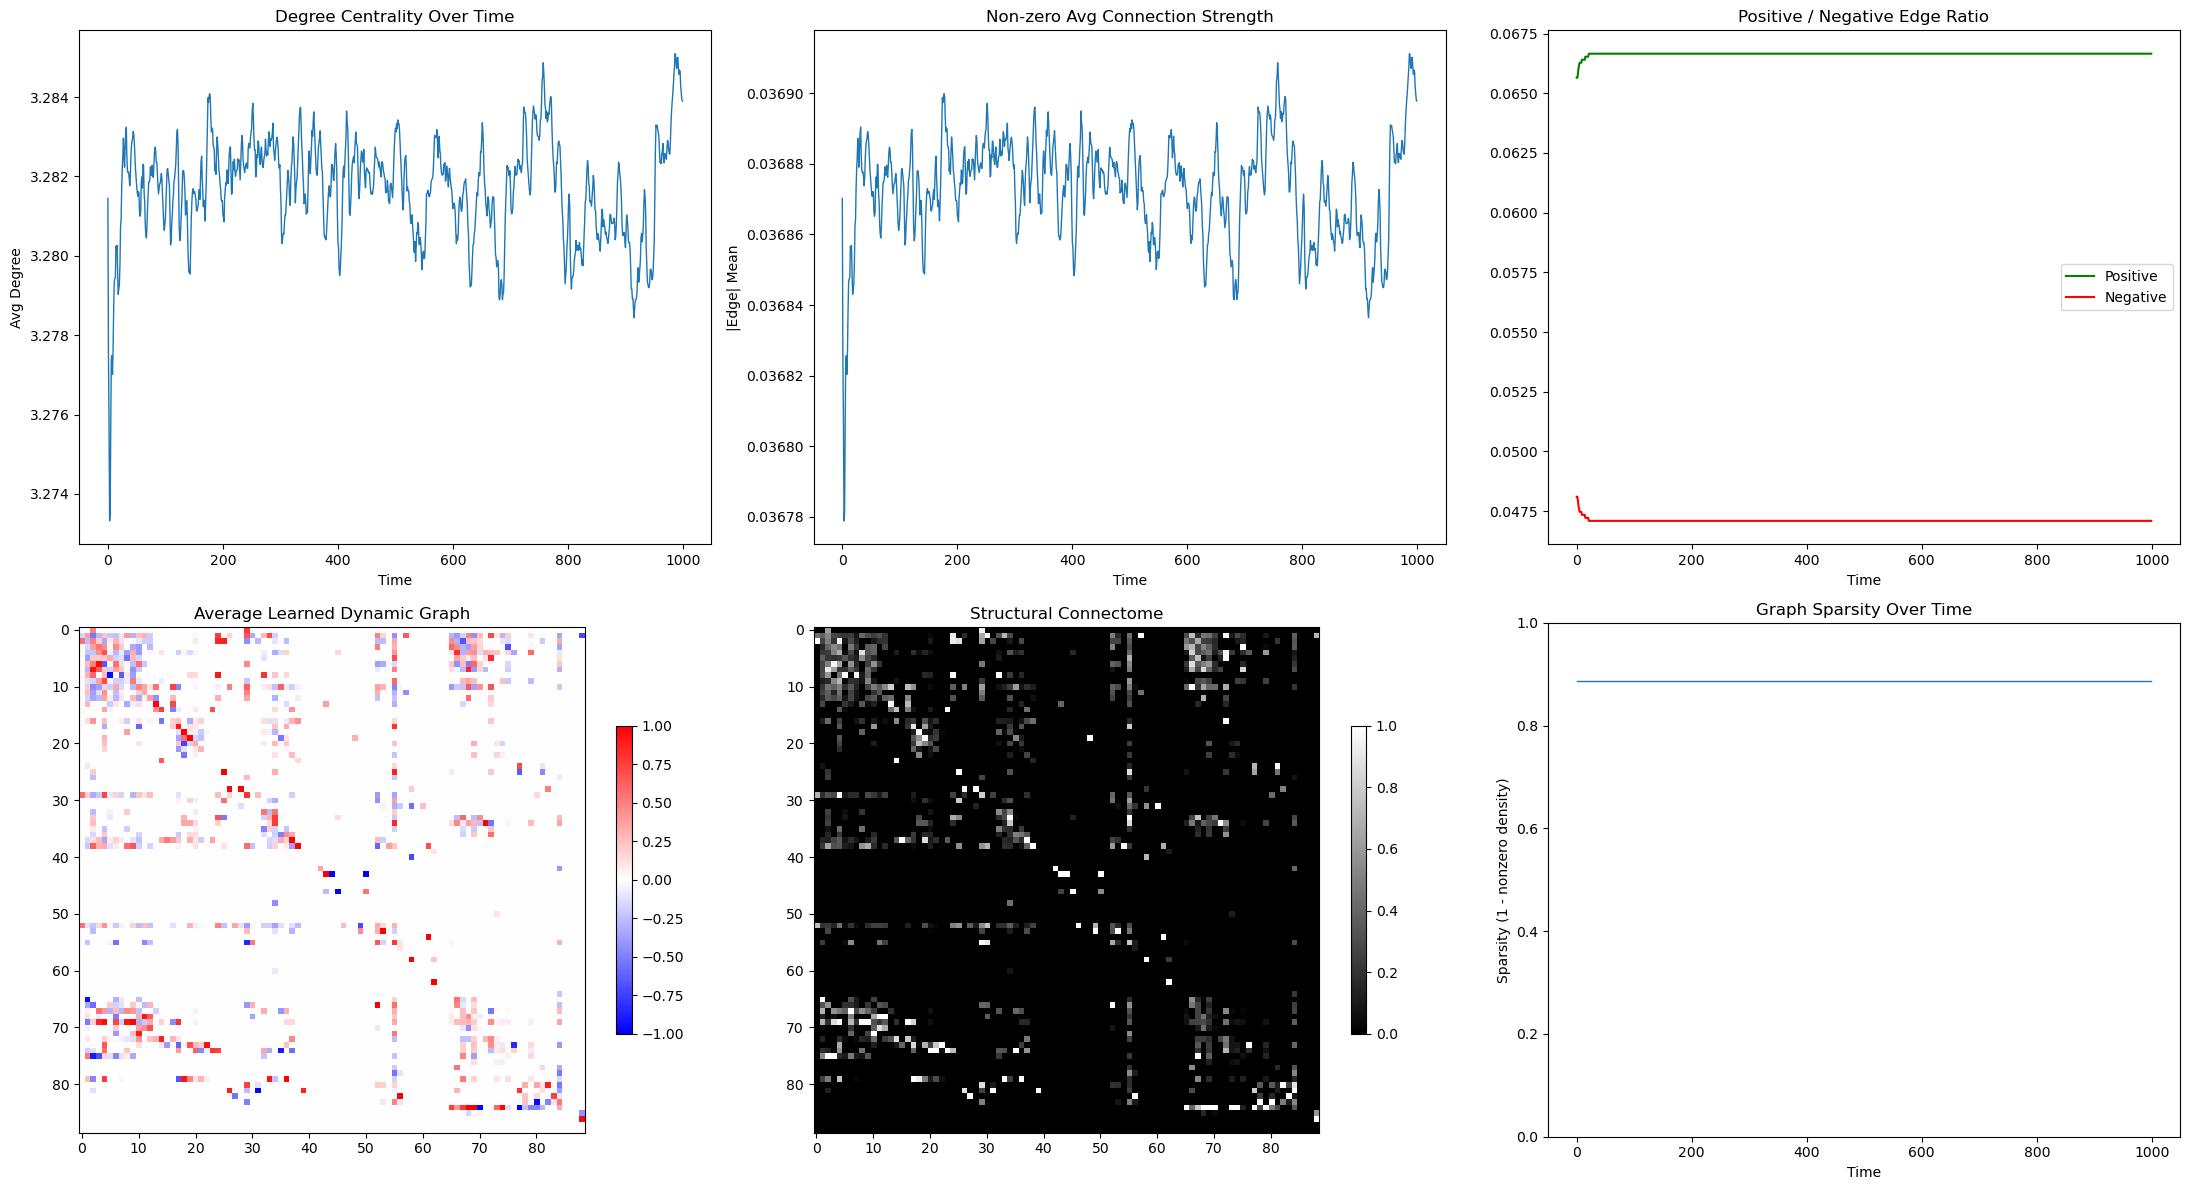

Saved figure to: ./result/wo_layer/stage1/dynamic_graph_analysis.png


'./result/wo_layer/stage1/dynamic_graph_analysis.png'

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import os

def plot_dynamic_graph_results(save_dir="./results"):

    if not os.path.exists(save_dir):
        raise FileNotFoundError(f"save_dir not found: {save_dir}")

    # -------- Load Files --------
    dyn_path = os.path.join(save_dir, "dynamic_full_graphs.npy")
    epoch_graphs_path = os.path.join(save_dir, "epoch_avg_graphs.npy")

    # dynamic graph
    dyn = np.load(dyn_path)   # (T, N, N)
    T, N, _ = dyn.shape

    # structural connectome
    struct = struct_connectome_array

    # epoch avg graphs
    epoch_graphs = np.load(epoch_graphs_path) if os.path.exists(epoch_graphs_path) else None

    # -------- Metrics --------
    degree = np.sum(np.abs(dyn), axis=2)
    mean_degree = np.mean(degree, axis=1)

    avg_strength = np.mean(np.abs(dyn), axis=(1,2))

    pos_ratio = np.sum(dyn > 0, axis=(1,2)) / (N*N)
    neg_ratio = np.sum(dyn < 0, axis=(1,2)) / (N*N)

    avg_graph = np.mean(dyn, axis=0)

    eps = 1e-4
    nonzero_ratio = np.sum(np.abs(dyn) > eps, axis=(1,2)) / (N*N)
    sparsity = 1 - nonzero_ratio

    # -------- Plot --------
    fig, axs = plt.subplots(2,3, figsize=(22,12))

    axs[0,0].plot(mean_degree, linewidth=1)
    axs[0,0].set_title("Degree Centrality Over Time")
    axs[0,0].set_xlabel("Time")
    axs[0,0].set_ylabel("Avg Degree")

    axs[0,1].plot(avg_strength, linewidth=1)
    axs[0,1].set_title("Non-zero Avg Connection Strength")
    axs[0,1].set_xlabel("Time")
    axs[0,1].set_ylabel("|Edge| Mean")

    axs[0,2].plot(pos_ratio, label="Positive", color="green")
    axs[0,2].plot(neg_ratio, label="Negative", color="red")
    axs[0,2].set_title("Positive / Negative Edge Ratio")
    axs[0,2].set_xlabel("Time")
    axs[0,2].legend()

    im1 = axs[1,0].imshow(avg_graph, cmap="bwr", vmin=-1, vmax=1)
    axs[1,0].set_title("Average Learned Dynamic Graph")
    plt.colorbar(im1, ax=axs[1,0], shrink=0.6)

    if struct is not None:
        im2 = axs[1,1].imshow(struct, cmap="gray")
        axs[1,1].set_title("Structural Connectome")
        plt.colorbar(im2, ax=axs[1,1], shrink=0.6)
    else:
        axs[1,1].text(0.5,0.5,"No Structural Matrix",ha='center',va='center')
        axs[1,1].set_title("Structural Connectome (missing)")

    axs[1,2].plot(sparsity, linewidth=1)
    axs[1,2].set_title("Graph Sparsity Over Time")
    axs[1,2].set_xlabel("Time")
    axs[1,2].set_ylabel("Sparsity (1 - nonzero density)")
    axs[1,2].set_ylim(0, 1)

    plt.tight_layout()

    # -------- Save --------
    fig_path = os.path.join(save_dir, "dynamic_graph_analysis.png")
    plt.savefig(fig_path, dpi=300, bbox_inches="tight")
    plt.show()

    print(f"Saved figure to: {fig_path}")
    return fig_path

plot_dynamic_graph_results(save_dir="./result/wo_layer/stage1/")

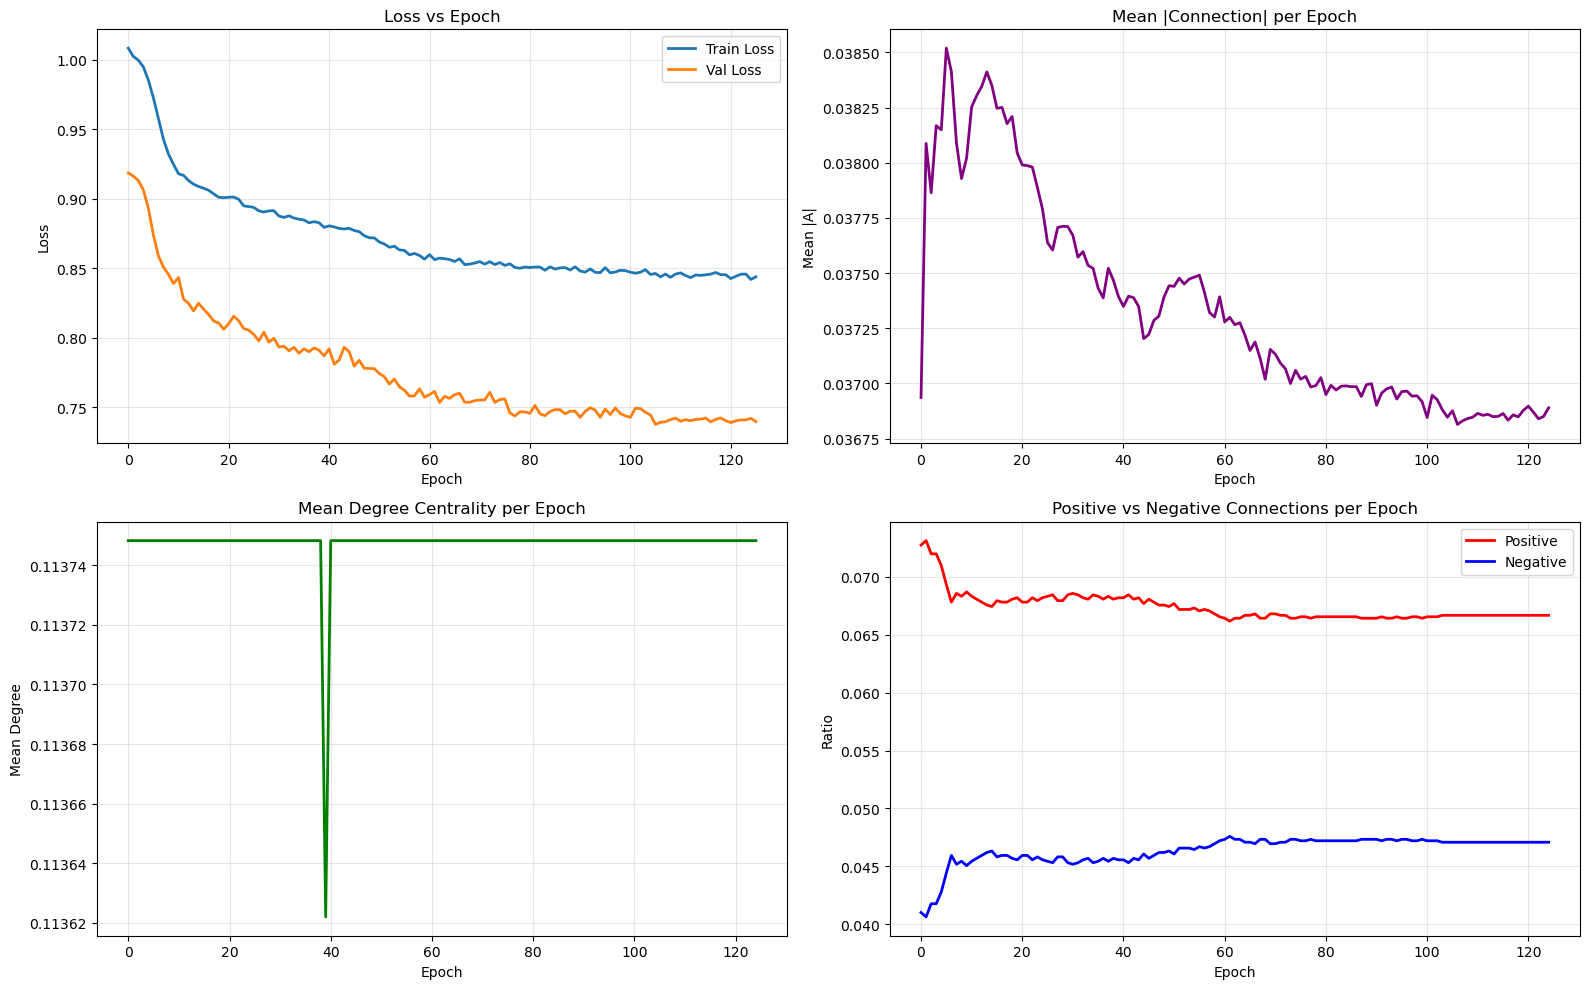

Saved: ./result/wo_layer/stage1/training_epoch_metric_plot.png


'./result/wo_layer/stage1/training_epoch_metric_plot.png'

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import os

def plot_training_epoch_metrics(save_dir="./results"):
    # -------- Check & load --------
    train_path = os.path.join(save_dir, "train_losses.npy")
    val_path   = os.path.join(save_dir, "val_losses.npy")
    epoch_graphs_path = os.path.join(save_dir, "epoch_avg_graphs.npy")

    if not os.path.exists(train_path) or not os.path.exists(val_path) or not os.path.exists(epoch_graphs_path):
        raise FileNotFoundError(f"Required files missing in {save_dir}:\n"
                                f"{train_path}\n{val_path}\n{epoch_graphs_path}")

    train_losses = np.load(train_path)
    val_losses   = np.load(val_path)
    epoch_graphs = np.load(epoch_graphs_path)   # shape (E, N, N)

    E, N, _ = epoch_graphs.shape

    # -------- Epoch metrics --------

    # Mean |A|
    epoch_mean_conn = np.mean(np.abs(epoch_graphs), axis=(1,2))

    # Degree = % edges > eps
    eps = 1e-4
    degree_epoch = np.mean((np.abs(epoch_graphs) > eps), axis=(1,2))

    # Pos / neg ratio
    pos_epoch = np.sum(epoch_graphs > 0, axis=(1,2)) / (N*N)
    neg_epoch = np.sum(epoch_graphs < 0, axis=(1,2)) / (N*N)

    # -------- Plot --------
    plt.figure(figsize=(16, 10))

    # 1. Loss curves
    plt.subplot(2,2,1)
    plt.plot(train_losses, label="Train Loss", linewidth=2)
    plt.plot(val_losses, label="Val Loss", linewidth=2)
    plt.title("Loss vs Epoch")
    plt.xlabel("Epoch"); plt.ylabel("Loss")
    plt.legend(); plt.grid(alpha=0.3)

    # 2. Mean |A|
    plt.subplot(2,2,2)
    plt.plot(epoch_mean_conn, color="purple", linewidth=2)
    plt.title("Mean |Connection| per Epoch")
    plt.xlabel("Epoch"); plt.ylabel("Mean |A|")
    plt.grid(alpha=0.3)

    # 3. Degree centrality
    plt.subplot(2,2,3)
    plt.plot(degree_epoch, color="green", linewidth=2)
    plt.title("Mean Degree Centrality per Epoch")
    plt.xlabel("Epoch"); plt.ylabel("Mean Degree")
    plt.grid(alpha=0.3)

    # 4. Pos vs Neg
    plt.subplot(2,2,4)
    plt.plot(pos_epoch, label="Positive", color="red", linewidth=2)
    plt.plot(neg_epoch, label="Negative", color="blue", linewidth=2)
    plt.title("Positive vs Negative Connections per Epoch")
    plt.xlabel("Epoch"); plt.ylabel("Ratio")
    plt.legend(); plt.grid(alpha=0.3)

    plt.tight_layout()

    # -------- Save --------
    fig_path = os.path.join(save_dir, "training_epoch_metric_plot.png")
    plt.savefig(fig_path, dpi=300)
    plt.show()

    print(f"Saved: {fig_path}")

    return fig_path
###############################
plot_training_epoch_metrics(save_dir="./result/wo_layer/stage1/")

## 2. Stage2

In [10]:
with open('brain_region_wo_layer_stage2.pkl', 'rb') as f:
    C_traces = pickle.load(f)
C_traces

{'MG': {'spike_times': array([1.32295741e-06, 2.22448016e-06, 4.46894026e-06, ...,
         9.99998459e-01, 9.99998823e-01, 1.00000000e+00]),
  'spike_voltages': array([1.02225975e-04, 1.90227904e-04, 6.86466592e-05, ...,
         1.46565464e-04, 1.36938193e-04, 8.16656393e-05])},
 'LGd': {'spike_times': array([0., 0., 0., ..., 1., 1., 1.]),
  'spike_voltages': array([1.15912066e-04, 2.21375594e-04, 2.84903537e-04, ...,
         7.53099230e-05, 1.34822039e-04, 6.84298866e-05])},
 'CEA': {'spike_times': array([9.88512933e-07, 3.90553693e-06, 7.73567368e-06, ...,
         9.99995064e-01, 9.99997947e-01, 9.99999048e-01]),
  'spike_voltages': array([2.71024008e-04, 1.77588983e-04, 8.60513755e-05, ...,
         1.29396503e-04, 9.81526682e-05, 5.01546710e-05])},
 'VPM': {'spike_times': array([4.29821969e-10, 5.48716916e-10, 1.60778299e-09, ...,
         1.00000000e+00, 1.00000000e+00, 1.00000000e+00]),
  'spike_voltages': array([0.00018025, 0.00016094, 0.00014604, ..., 0.00022785, 0.00015073

Automatically set line spacing: 2.20


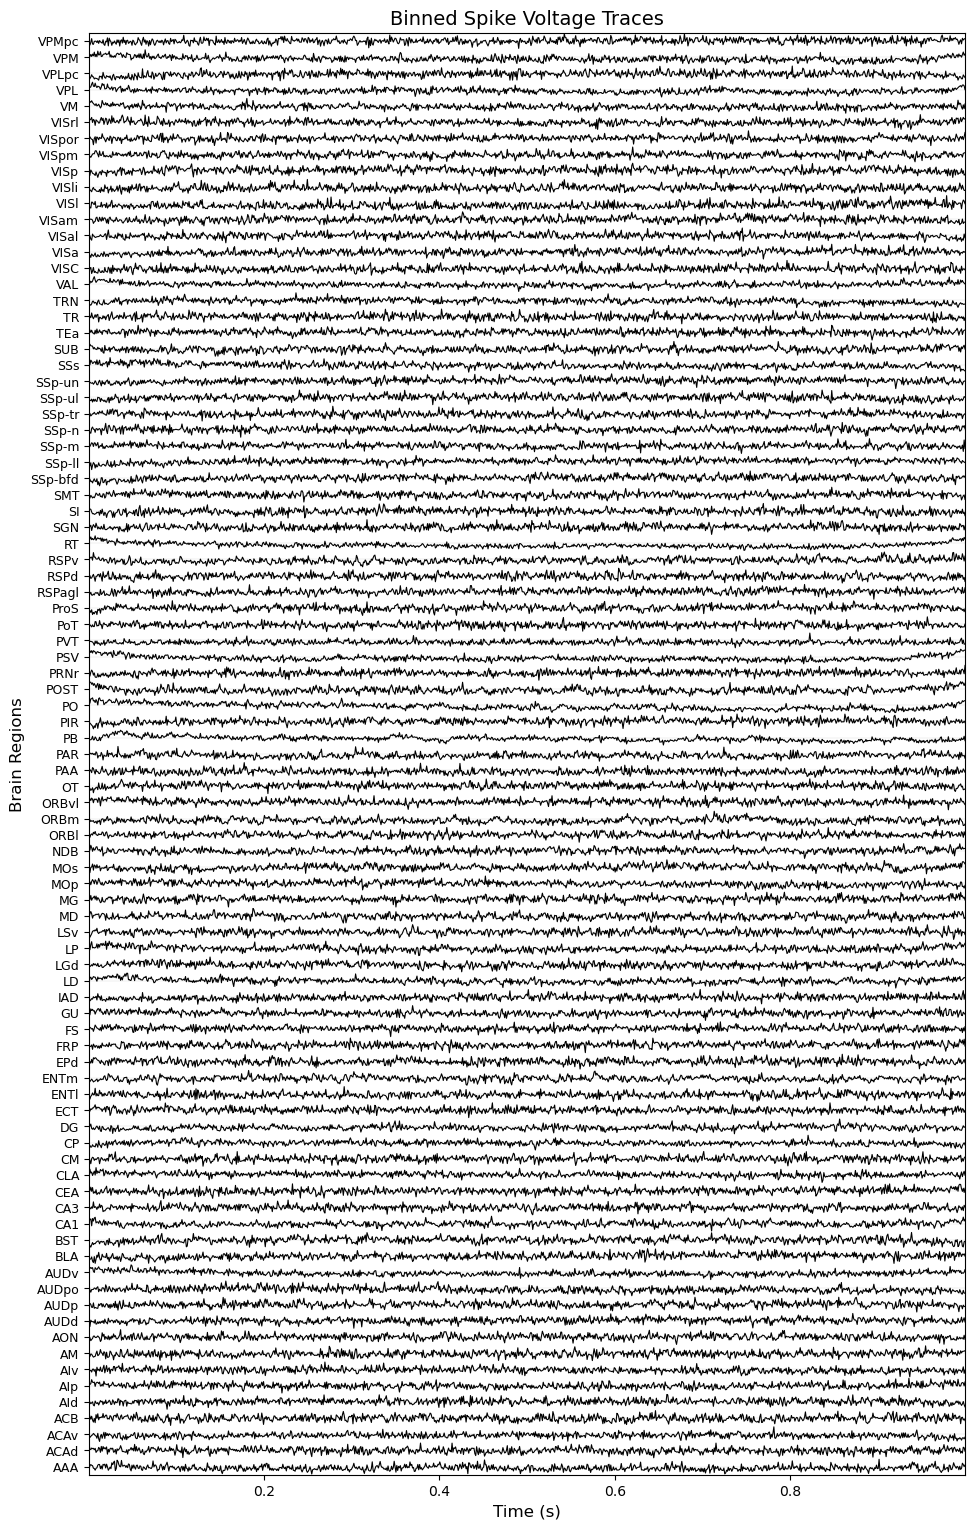

In [11]:
C_traces_sorted = {k: C_traces[k] for k in df_scaled.index if k in C_traces}
time_axis, binned_traces, duration = build_region_binned_traces_nan(C_traces_sorted, dt=0.001)
plot_brain_region_traces(binned_traces, time_axis, output_dir="result/wo_layer/stage2")

In [ ]:
struct_connectome_array = df_scaled.values
binned_traces_array = np.array([binned_traces[key] for key in sorted(binned_traces.keys())])
binned_traces_array = np.nan_to_num(binned_traces_array, nan=0.0)

import itertools
import os

# ====== Hyperparam grids ======
batch_sizes = [8, 16, 32, 64]
dropouts = [0.1, 0.3, 0.6, 0.8]
struct_weights = [0.1, 0.5, 0.7, 1.0]

# ====== Loop over all combinations ======
for bs, dp, sw in itertools.product(batch_sizes, dropouts, struct_weights):

    # 生成保存目录名称：比如 bs32_dp0.6_sw0.5
    save_dir = f"./result/wo_layer/stage2/tuning/bs{bs}_dp{dp}_sw{sw}"
    os.makedirs(save_dir, exist_ok=True)

    print("="*60)
    print(f"Training with batch_size={bs}, dropout={dp}, struct_constraint_weight={sw}")
    print(f"Save dir: {save_dir}")
    print("="*60)

    model, train_losses, val_losses, full_dynamic_graphs = train_timeseries_dynamic_graph(
        cell_trace = binned_traces_array,
        struct_connectome = struct_connectome_array,
        seq_length = 50,
        pred_length = 10,
        hidden_dim = 32,
        lr = 1e-3,
        epochs = 300,
        batch_size = bs,
        dropout = dp,
        device = None,
        seed = 42,
        val_ratio = 0.2,
        patience = 20,   
        heads = 4,
        head_dim = 8,
        embed_dim = 10,
        struct_constraint_weight = sw,
        save_dir = save_dir
    )

    # 再保存曲线
    np.save(f"{save_dir}/train_losses.npy", np.array(train_losses))
    np.save(f"{save_dir}/val_losses.npy", np.array(val_losses))

    print(f"Finished: bs={bs} dp={dp} sw={sw} | Saved to {save_dir}")

Training with batch_size=8, dropout=0.1, struct_constraint_weight=0.1
Save dir: ./result/wo_layer/stage2/tuning/bs8_dp0.1_sw0.1
Training start | seq=50, T=1000


/home/ylx/anaconda3/envs/ibl_bwm/lib/python3.10/site-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 20/300 | Train 0.32811 | Val 0.39986
Epoch 40/300 | Train 0.31279 | Val 0.38584
Epoch 60/300 | Train 0.30599 | Val 0.39118


/tmp/ipykernel_2152023/996028222.py:334: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  engine.model.load_state_dict(torch.load(f"{save_dir}/best_model.pth"))


Early stop @ epoch 73
Training done, loading best model
Saved epoch_avg_graphs.npy to ./result/wo_layer/stage2/tuning/bs8_dp0.1_sw0.1
Reconstructing full dynamic graph...


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 951/951 [00:25<00:00, 36.61it/s]


Saved dynamic_full_graphs.npy to ./result/wo_layer/stage2/tuning/bs8_dp0.1_sw0.1, shape=(1000, 89, 89)
Finished: bs=8 dp=0.1 sw=0.1 | Saved to ./result/wo_layer/stage2/tuning/bs8_dp0.1_sw0.1
Training with batch_size=8, dropout=0.1, struct_constraint_weight=0.5
Save dir: ./result/wo_layer/stage2/tuning/bs8_dp0.1_sw0.5
Training start | seq=50, T=1000
Epoch 20/300 | Train 0.32916 | Val 0.39987
Epoch 40/300 | Train 0.31209 | Val 0.38479
Early stop @ epoch 59
Training done, loading best model
Saved epoch_avg_graphs.npy to ./result/wo_layer/stage2/tuning/bs8_dp0.1_sw0.5
Reconstructing full dynamic graph...


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 951/951 [00:25<00:00, 36.87it/s]


Saved dynamic_full_graphs.npy to ./result/wo_layer/stage2/tuning/bs8_dp0.1_sw0.5, shape=(1000, 89, 89)
Finished: bs=8 dp=0.1 sw=0.5 | Saved to ./result/wo_layer/stage2/tuning/bs8_dp0.1_sw0.5
Training with batch_size=8, dropout=0.1, struct_constraint_weight=0.7
Save dir: ./result/wo_layer/stage2/tuning/bs8_dp0.1_sw0.7
Training start | seq=50, T=1000
Epoch 20/300 | Train 0.33591 | Val 0.41482
Epoch 40/300 | Train 0.31737 | Val 0.39452
Epoch 60/300 | Train 0.31087 | Val 0.39529
Epoch 80/300 | Train 0.30614 | Val 0.38597
Epoch 100/300 | Train 0.30194 | Val 0.37946
Early stop @ epoch 109
Training done, loading best model
Saved epoch_avg_graphs.npy to ./result/wo_layer/stage2/tuning/bs8_dp0.1_sw0.7
Reconstructing full dynamic graph...


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 951/951 [00:25<00:00, 36.86it/s]


Saved dynamic_full_graphs.npy to ./result/wo_layer/stage2/tuning/bs8_dp0.1_sw0.7, shape=(1000, 89, 89)
Finished: bs=8 dp=0.1 sw=0.7 | Saved to ./result/wo_layer/stage2/tuning/bs8_dp0.1_sw0.7
Training with batch_size=8, dropout=0.1, struct_constraint_weight=1.0
Save dir: ./result/wo_layer/stage2/tuning/bs8_dp0.1_sw1.0
Training start | seq=50, T=1000
Epoch 20/300 | Train 0.32826 | Val 0.40314


In [15]:
struct_connectome_array = df_scaled.values
binned_traces_array = np.array([binned_traces[key] for key in sorted(binned_traces.keys())])
binned_traces_array = np.nan_to_num(binned_traces_array, nan=0.0)

if __name__ == "__main__":
    print("Time-series dynamic graph learning network")
    print("=" * 50)
    print("Data format:")
    print("- cell_trace: (num_regions, time_steps)")
    print("- struct_connectome: (num_regions, num_regions)")
    print("=" * 50)

    # ====== Date input ======
    cell_trace = binned_traces_array            
    struct_connectome = struct_connectome_array 

    # ====== Call the training function ======
    model, train_losses, val_losses, full_dynamic_graphs = train_timeseries_dynamic_graph(
        cell_trace = cell_trace,
        struct_connectome = struct_connectome,
        seq_length = 50,          
        pred_length = 10,         
        hidden_dim = 32,
        lr = 1e-3,
        epochs = 500,
        batch_size = 32,
        dropout = 0.6,
        device = None,
        seed = 42,
        val_ratio = 0.2,
        patience = 20,
        heads = 4,
        head_dim = 8,
        embed_dim = 10,
        struct_constraint_weight = 0.5,
        save_dir="./result/wo_layer/stage2"
    )

    print("Training complete!")
    print("Dynamic network shape:", full_dynamic_graphs.shape)  # → (T, N, N)
    print("Number of frames =", full_dynamic_graphs.shape[0])

    print("Training curve length:", len(train_losses), len(val_losses))

Time-series dynamic graph learning network
Data format:
- cell_trace: (num_regions, time_steps)
- struct_connectome: (num_regions, num_regions)
Training start | seq=50, T=1000


/home/ylx/anaconda3/envs/ibl_bwm/lib/python3.10/site-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 20/500 | Train 0.80667 | Val 1.15206
Epoch 40/500 | Train 0.77756 | Val 1.10635


/tmp/ipykernel_3881356/1642340253.py:333: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  engine.model.load_state_dict(torch.load(f"{save_dir}/best_model.pth"))


Early stop @ epoch 53
Training done, loading best model
Saved epoch_avg_graphs.npy to ./result/wo_layer/stage2
Reconstructing full dynamic graph...


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 951/951 [01:15<00:00, 12.64it/s]

Saved dynamic_full_graphs.npy to ./result/wo_layer/stage2, shape=(1000, 89, 89)
Training complete!
Dynamic network shape: (1000, 89, 89)
Number of frames = 1000
Training curve length: 53 53


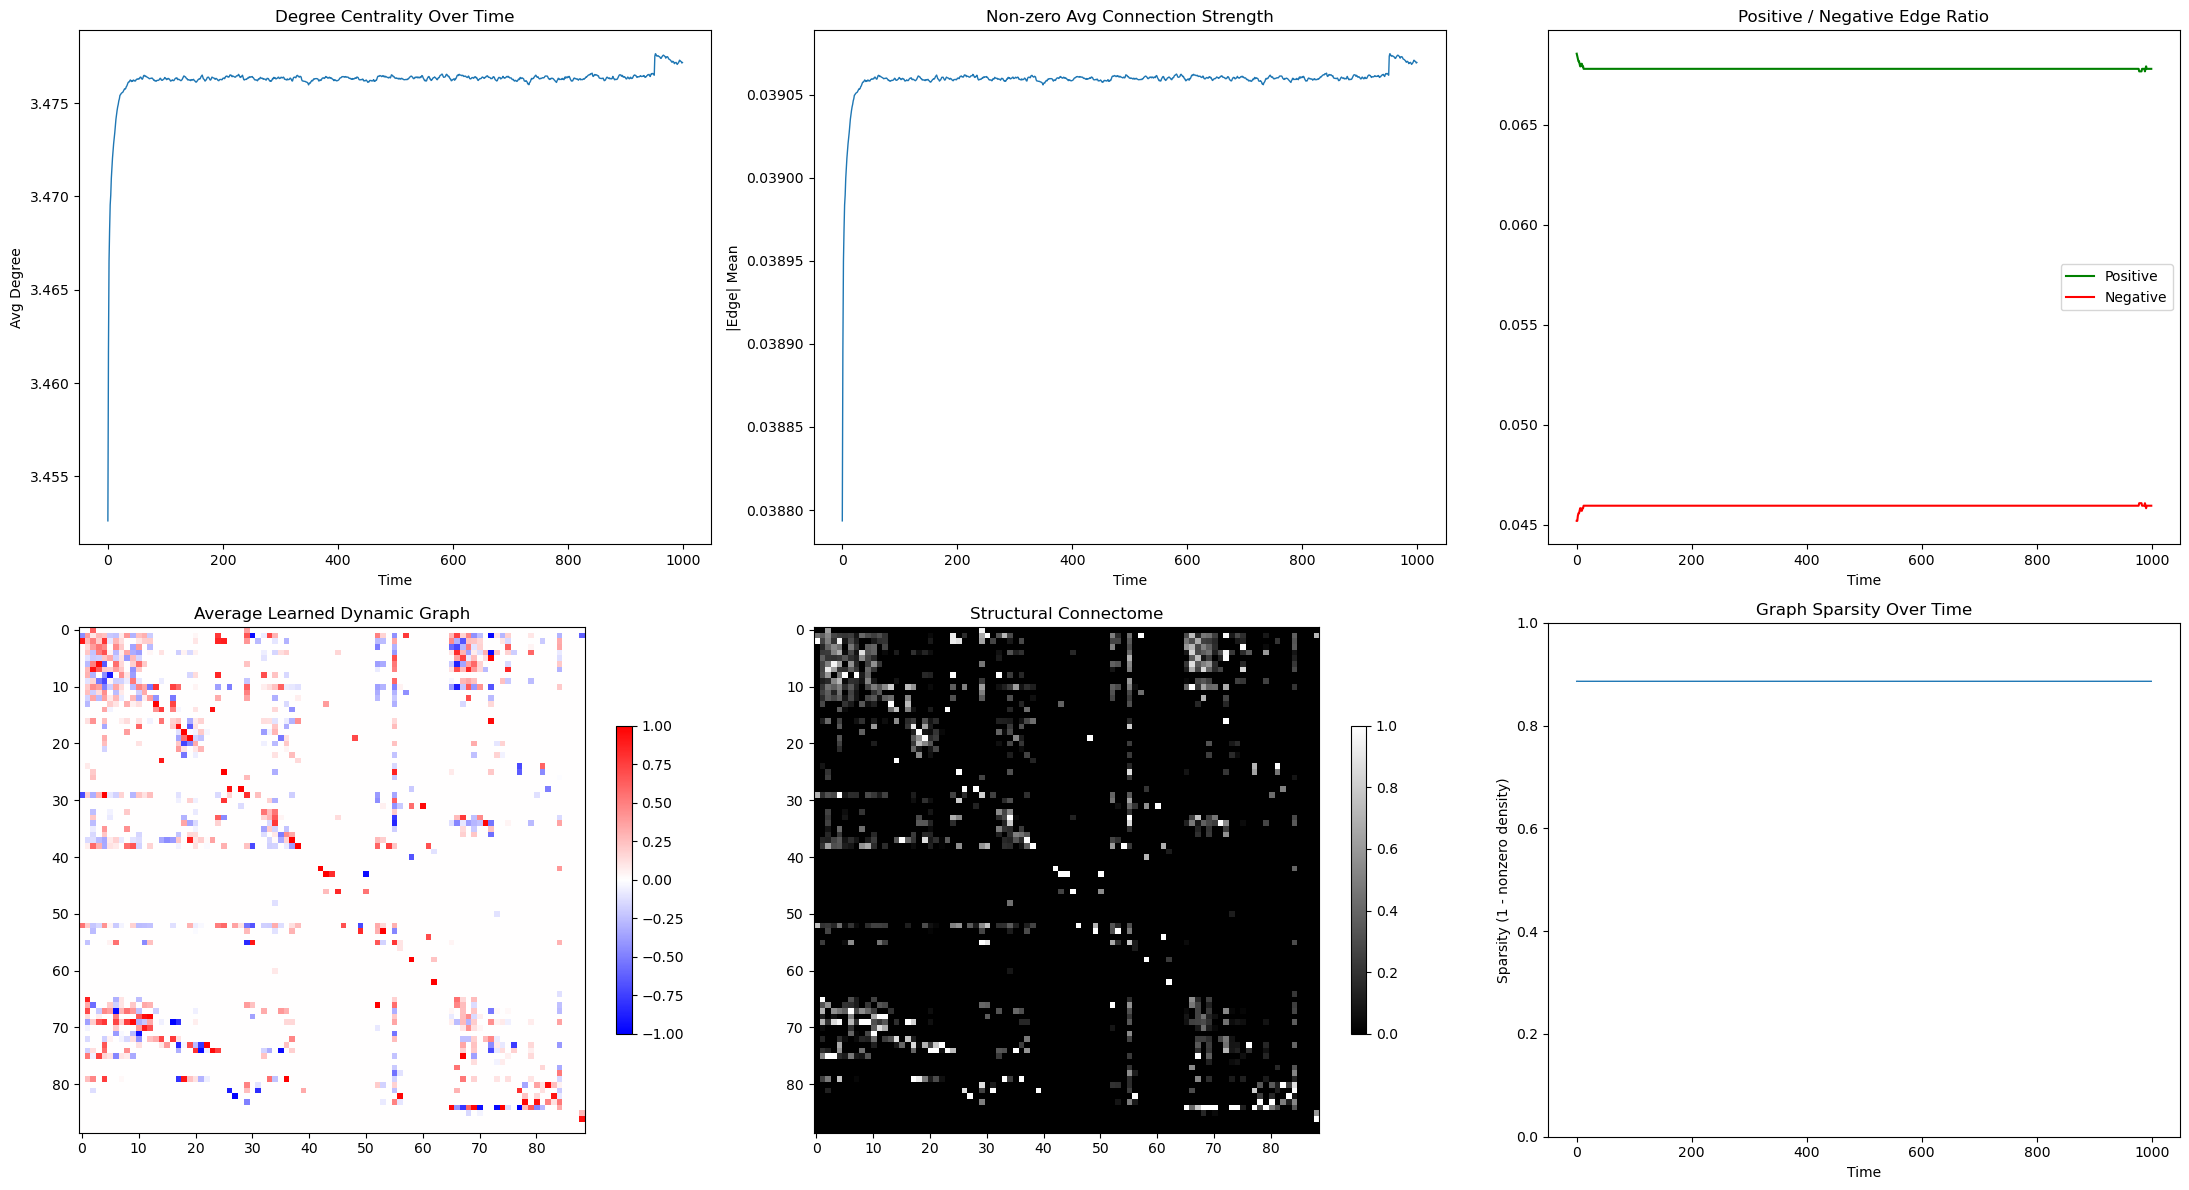

Saved figure to: ./result/wo_layer/stage2/dynamic_graph_analysis.png


'./result/wo_layer/stage2/dynamic_graph_analysis.png'

In [16]:
plot_dynamic_graph_results(save_dir="./result/wo_layer/stage2/")

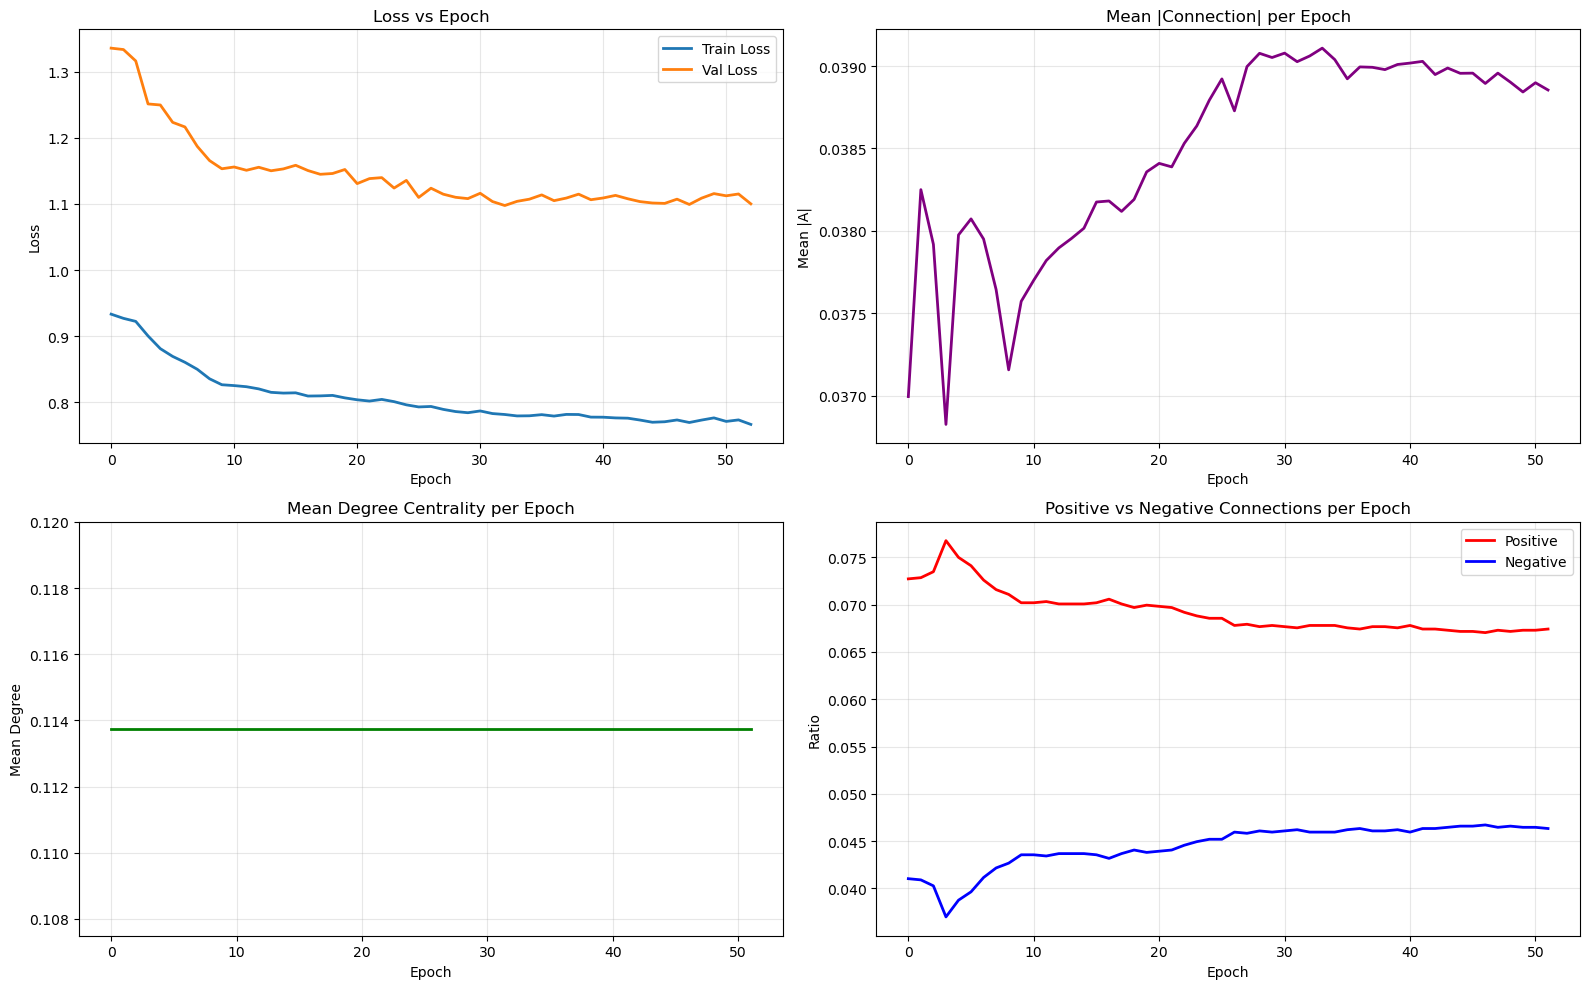

Saved: ./result/wo_layer/stage2/training_epoch_metric_plot.png


'./result/wo_layer/stage2/training_epoch_metric_plot.png'

In [17]:
plot_training_epoch_metrics(save_dir="./result/wo_layer/stage2/")

## 3. Stage3

In [ ]:
with open('brain_region_wo_layer_stage3.pkl', 'rb') as f:
    C_traces = pickle.load(f)
C_traces

In [ ]:
C_traces_sorted = {k: C_traces[k] for k in df_scaled.index if k in C_traces}
time_axis, binned_traces, duration = build_region_binned_traces_nan(C_traces_sorted, dt=0.001)
plot_brain_region_traces(binned_traces, time_axis, output_dir="result/wo_layer/stage3")

In [ ]:
struct_connectome_array = df_scaled.values
binned_traces_array = np.array([binned_traces[key] for key in sorted(binned_traces.keys())])
binned_traces_array = np.nan_to_num(binned_traces_array, nan=0.0)

import itertools
import os

# ====== Hyperparam grids ======
batch_sizes = [8, 16, 32, 64]
dropouts = [0.1, 0.3, 0.6, 0.8]
struct_weights = [0.1, 0.5, 0.7, 1.0]

# ====== Loop over all combinations ======
for bs, dp, sw in itertools.product(batch_sizes, dropouts, struct_weights):

    # 生成保存目录名称：比如 bs32_dp0.6_sw0.5
    save_dir = f"./result/wo_layer/stage3/tuning/bs{bs}_dp{dp}_sw{sw}"
    os.makedirs(save_dir, exist_ok=True)

    print("="*60)
    print(f"Training with batch_size={bs}, dropout={dp}, struct_constraint_weight={sw}")
    print(f"Save dir: {save_dir}")
    print("="*60)

    model, train_losses, val_losses, full_dynamic_graphs = train_timeseries_dynamic_graph(
        cell_trace = binned_traces_array,
        struct_connectome = struct_connectome_array,
        seq_length = 50,
        pred_length = 10,
        hidden_dim = 32,
        lr = 1e-3,
        epochs = 300,
        batch_size = bs,
        dropout = dp,
        device = None,
        seed = 42,
        val_ratio = 0.2,
        patience = 20,   
        heads = 4,
        head_dim = 8,
        embed_dim = 10,
        struct_constraint_weight = sw,
        save_dir = save_dir
    )

    # 再保存曲线
    np.save(f"{save_dir}/train_losses.npy", np.array(train_losses))
    np.save(f"{save_dir}/val_losses.npy", np.array(val_losses))

    print(f"Finished: bs={bs} dp={dp} sw={sw} | Saved to {save_dir}")

In [21]:
struct_connectome_array = df_scaled.values
binned_traces_array = np.array([binned_traces[key] for key in sorted(binned_traces.keys())])
binned_traces_array = np.nan_to_num(binned_traces_array, nan=0.0)

if __name__ == "__main__":
    print("Time-series dynamic graph learning network")
    print("=" * 50)
    print("Data format:")
    print("- cell_trace: (num_regions, time_steps)")
    print("- struct_connectome: (num_regions, num_regions)")
    print("=" * 50)

    # ====== Date input ======
    cell_trace = binned_traces_array            
    struct_connectome = struct_connectome_array 

    # ====== Call the training function ======
    model, train_losses, val_losses, full_dynamic_graphs = train_timeseries_dynamic_graph(
        cell_trace = cell_trace,
        struct_connectome = struct_connectome,
        seq_length = 50,          
        pred_length = 10,         
        hidden_dim = 32,
        lr = 1e-3,
        epochs = 500,
        batch_size = 32,
        dropout = 0.6,
        device = None,
        seed = 42,
        val_ratio = 0.2,
        patience = 20,
        heads = 4,
        head_dim = 8,
        embed_dim = 10,
        struct_constraint_weight = 0.5,
        save_dir="./result/wo_layer/stage3"
    )

    print("Training complete!")
    print("Dynamic network shape:", full_dynamic_graphs.shape)  # → (T, N, N)
    print("Number of frames =", full_dynamic_graphs.shape[0])

    print("Training curve length:", len(train_losses), len(val_losses))

Time-series dynamic graph learning network
Data format:
- cell_trace: (num_regions, time_steps)
- struct_connectome: (num_regions, num_regions)
Training start | seq=50, T=1000


/home/ylx/anaconda3/envs/ibl_bwm/lib/python3.10/site-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 20/500 | Train 0.89025 | Val 0.67679
Epoch 40/500 | Train 0.86147 | Val 0.65236
Epoch 60/500 | Train 0.83896 | Val 0.62540
Epoch 80/500 | Train 0.82122 | Val 0.60580
Epoch 100/500 | Train 0.81988 | Val 0.60708
Epoch 120/500 | Train 0.81031 | Val 0.60264


/tmp/ipykernel_3881356/1642340253.py:333: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  engine.model.load_state_dict(torch.load(f"{save_dir}/best_model.pth"))


Early stop @ epoch 132
Training done, loading best model
Saved epoch_avg_graphs.npy to ./result/wo_layer/stage3
Reconstructing full dynamic graph...


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 951/951 [01:06<00:00, 14.26it/s]


Saved dynamic_full_graphs.npy to ./result/wo_layer/stage3, shape=(1000, 89, 89)
Training complete!
Dynamic network shape: (1000, 89, 89)
Number of frames = 1000
Training curve length: 132 132


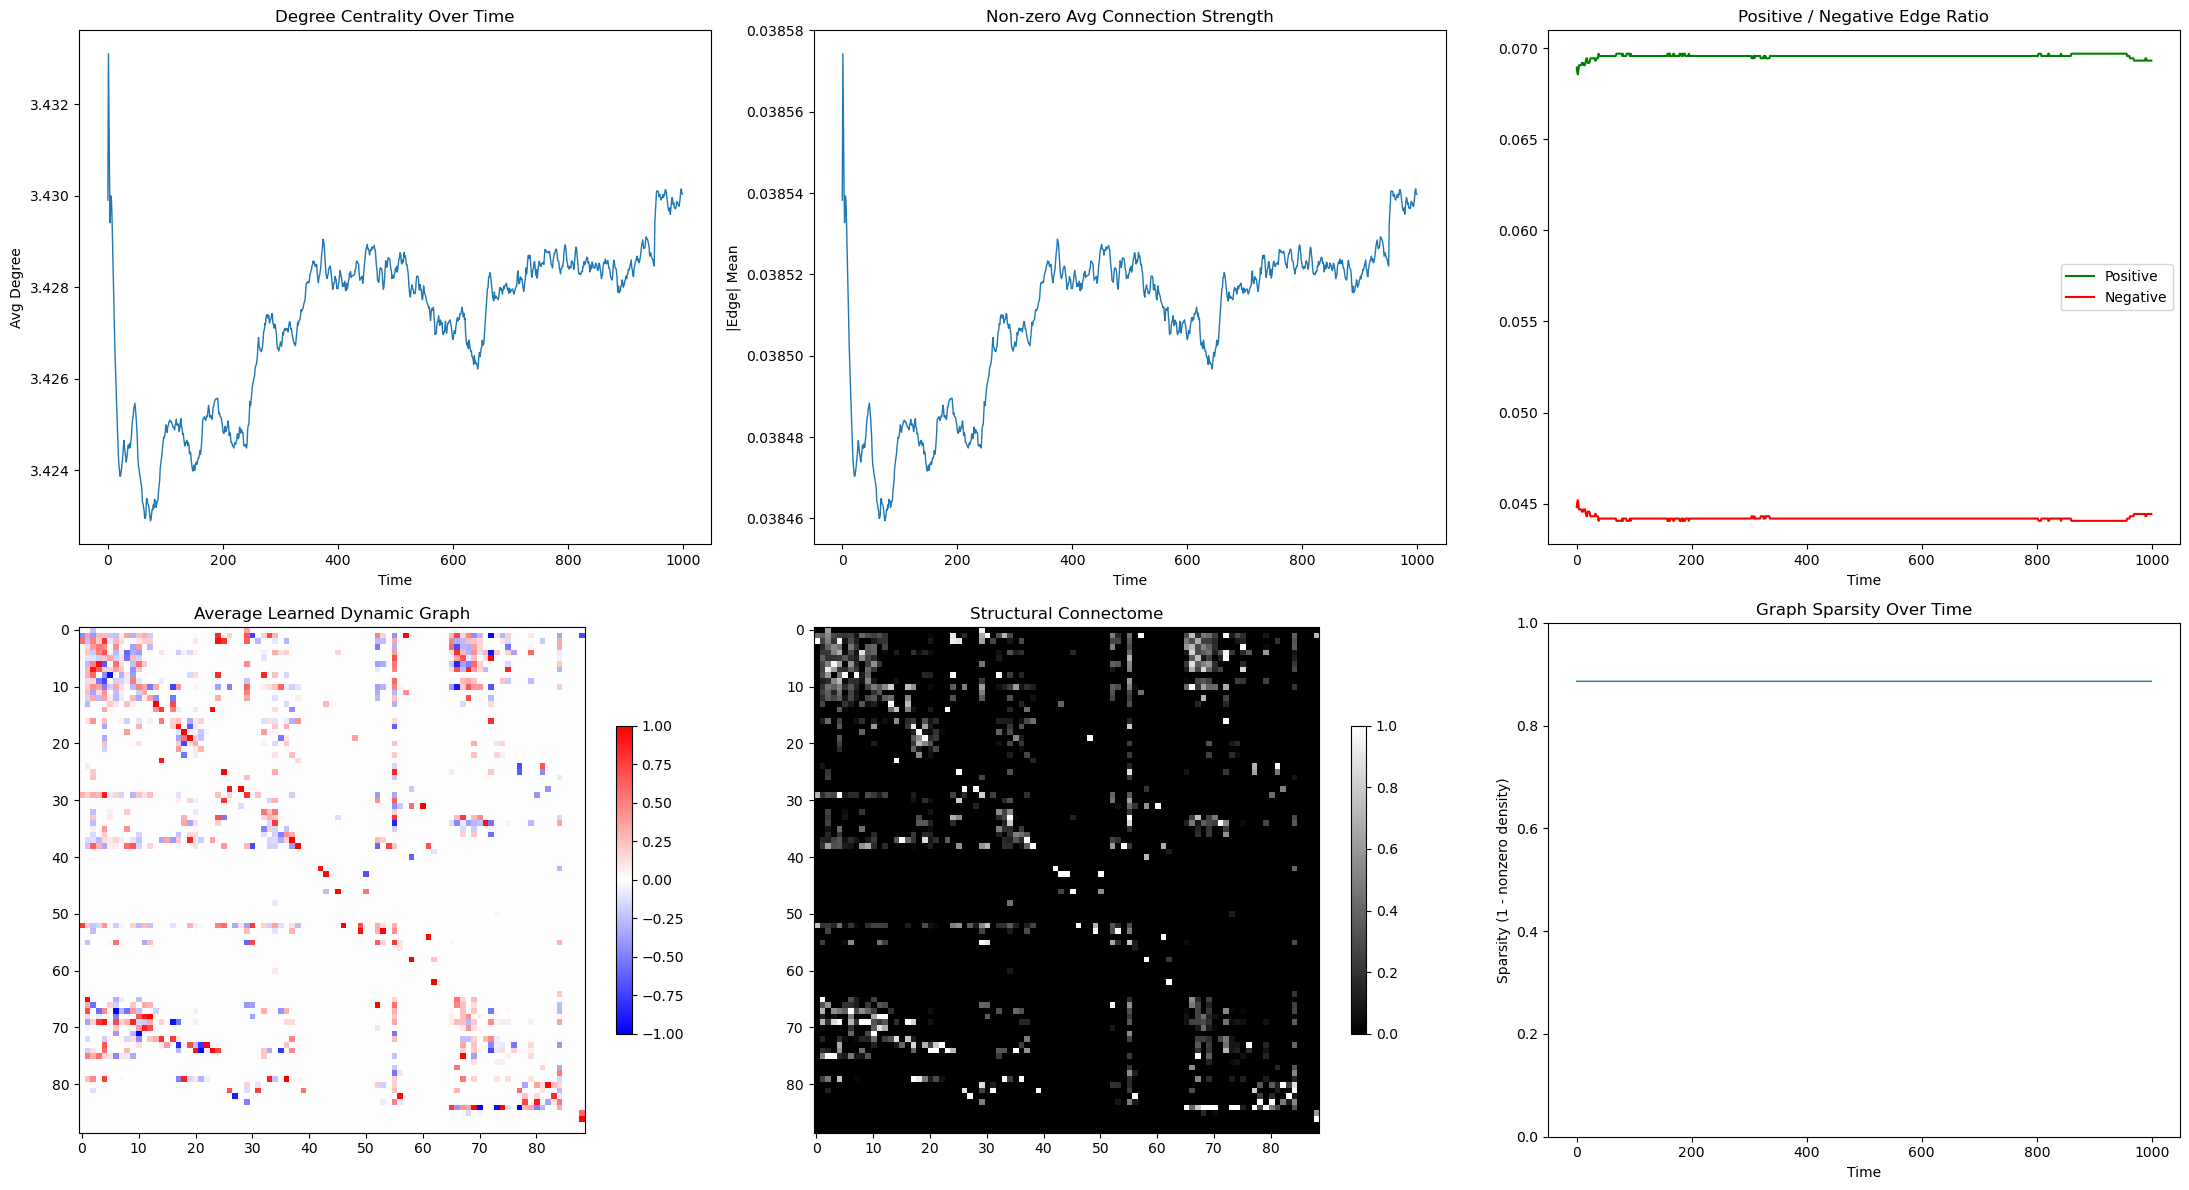

Saved figure to: ./result/wo_layer/stage3/dynamic_graph_analysis.png


'./result/wo_layer/stage3/dynamic_graph_analysis.png'

In [22]:
plot_dynamic_graph_results(save_dir="./result/wo_layer/stage3/")

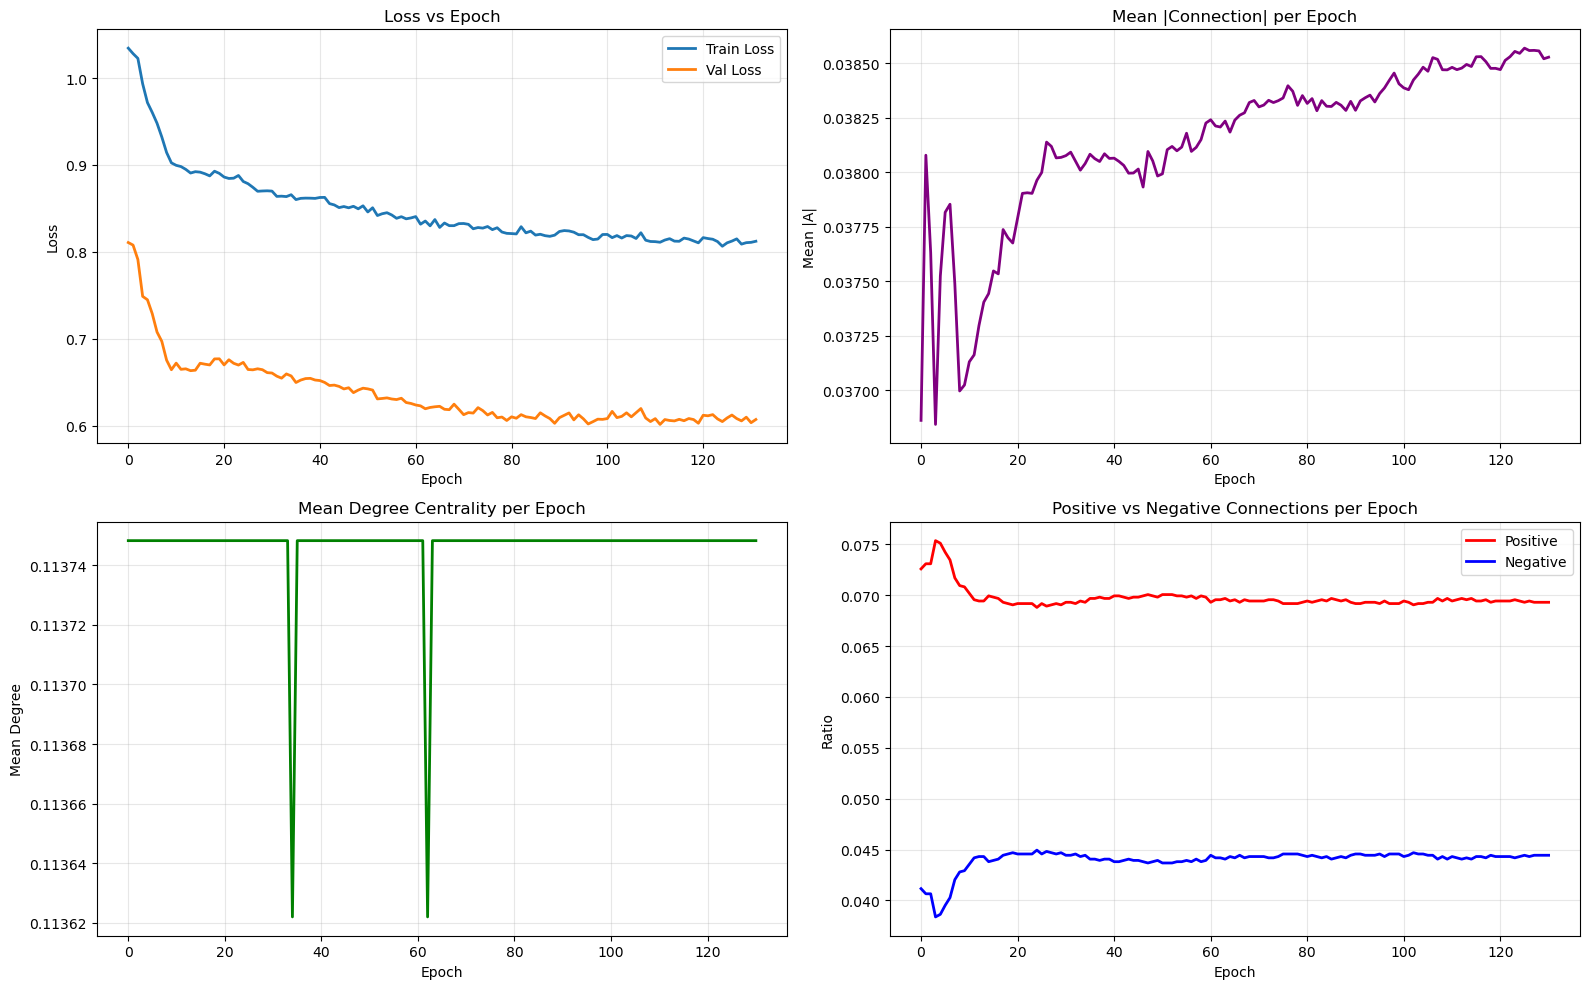

Saved: ./result/wo_layer/stage3/training_epoch_metric_plot.png


'./result/wo_layer/stage3/training_epoch_metric_plot.png'

In [23]:
plot_training_epoch_metrics(save_dir="./result/wo_layer/stage3/")